# Experiments: data pipeline, models and the (n, m) sweep

**ECS 171 - Does Naive Bayes Really Learn in O(log n)?** (Andrew Ngo, Kevin Liu, Bryce Lee)

This notebook builds the experiment pipeline described in our EDA (`EDA.ipynb`), trains naive Bayes and logistic regression over a grid of vocabulary sizes n and training sizes m, and saves one result row per (n, m, split, model).

Data:
* `SMSSpamCollection.csv` - UCI SMS Spam Collection
* `enron_spam_data.csv` - Enron-Spam (Metsis et al., 2006), combined-CSV of all six folders.

Outputs:
* `{sms,enron}/raw/n####.csv` - one row per (n, m, split, model), with the config that produced it next to it
* `{sms,enron}/summary_*.csv` - mean and 95% CI per (n, model, m)

The sweeps are slow (SMS takes minutes, Enron takes hours). A sweep cell skips any (n, model) already saved in `results/`, so re-running the notebook only repeats the short diagnostic cells.

In [1]:
import json
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from matplotlib.ticker import FuncFormatter
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import BernoulliNB, MultinomialNB

DATA = Path("data/raw")
PROCESSED = Path("data/processed")
RESULTS = Path("results")

SEED = 171            # every split in this notebook derives from this seed
DEV_FRAC = 0.2        # share of each corpus used only to rank the vocabulary
N_SPLITS = 200        # Monte Carlo train/test splits per corpus
M_MIN, PER_OCTAVE = 8, 2      # training sizes: from 8, two per doubling, up to the whole non-test pool
SMS_N = [16, 32, 64, 128, 256, 512, 1024, 2048]
ENRON_N = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2,
})
pd.set_option("display.width", 200)


def banner(title):
    print("\n" + "=" * 100 + f"\n{title}\n" + "=" * 100)

## 1. Feasibility of Current Design

Our proposal currently uses SMS Spam only, with n from 16 to 4,096, and assumed the crossover m*(n) would be visible for every n. We can check the math first without running the pipeline: reserve a 20% dev split for the vocabulary and a 1,000-message test set, then ask for each n whether the dev split has n distinct tokens and whether a crossover near c × n would fit inside the largest training set.

In [ ]:
TOKEN_RE = re.compile(r"[a-z0-9]+|[£$€!]")     # tokenizer chosen in the EDA

#Reads and parses the raw SMS span Collection dataset file into a list a of (text, is_spam) tuples
def read_sms():
    path = next(p for p in (DATA / "SMSSpamCollection", DATA / "SMSSpamCollection.csv") if p.exists())
    rows = []
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            label, text = line.split("\t", 1)
            if label not in ("ham", "spam"):
                raise ValueError(f"unexpected label {label!r}")
            rows.append((text, label == "spam"))
    return rows

#Normalizes text to create a duplicate key from the EDA
def norm_key(text):
    return " ".join(text.lower().split())


raw_rows = read_sms()
raw_texts = [t for t, _ in raw_rows]
raw_y = np.array([s for _, s in raw_rows], dtype=int)
n_unique = len({norm_key(t) for t in raw_texts})
print(f"messages: {len(raw_y):,}   spam: {raw_y.sum():,} ({raw_y.mean():.1%})   after removing exact duplicates: {n_unique:,}")

rng = np.random.default_rng(SEED)
dev = rng.permutation(len(raw_y))[: round(DEV_FRAC * len(raw_y))]
dev_vocab = {tok for i in dev for tok in TOKEN_RE.findall(raw_texts[i].lower())}
pool_size = n_unique - round(DEV_FRAC * n_unique)
m_max = pool_size - 1000
print(f"20% dev split: {len(dev):,} messages with {len(dev_vocab):,} distinct tokens")
print(f"pool (deduplicated, minus dev): about {pool_size:,}  ->  largest training set m_max about {m_max:,}\n")

print(f"{'n':>6} {'n tokens in dev?':>17} {'m_max / n':>10}   crossover visible if m* is about c x n, for c in")
for n in [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]:
    visible = [c for c in (0.5, 1, 2, 5, 10) if c * n <= m_max]
    print(f"{n:>6} {'yes' if n <= len(dev_vocab) else 'NO':>17} {m_max / n:>10.2f}   {visible if visible else 'none'}")

messages: 5,574   spam: 747 (13.4%)   after removing exact duplicates: 5,159
20% dev split: 1,115 messages with 3,627 distinct tokens
pool (deduplicated, minus dev): about 4,127  ->  largest training set m_max about 3,127

     n  n tokens in dev?  m_max / n   crossover visible if m* is about c x n, for c in
    16               yes     195.44   [0.5, 1, 2, 5, 10]
    32               yes      97.72   [0.5, 1, 2, 5, 10]
    64               yes      48.86   [0.5, 1, 2, 5, 10]
   128               yes      24.43   [0.5, 1, 2, 5, 10]
   256               yes      12.21   [0.5, 1, 2, 5, 10]
   512               yes       6.11   [0.5, 1, 2, 5]
  1024               yes       3.05   [0.5, 1, 2]
  2048               yes       1.53   [0.5, 1]
  4096                NO       0.76   [0.5]


The dev split supports vocabularies only up to about 3,600 tokens, so n = 4,096 is out of reach on SMS.  Training data, not vocabulary, is the constraint for the largest n.

* Largest training set (~3,127 messages) is 12× n at n = 256 but only 1.5× n at n = 2,048, little headroom for a crossover to appear at the largest n, if LR needs on the order of n examples to overtake NB.
* Plan: sweep n = 16 to 2,048; record any crossover not reached within the data as a lower bound.

## 2. Data Pipeline

### 2.1 Trying `CountVectorizer` on every message

We will first use the pre-existing scikit-learn pipeline: load the raw file, fit `CountVectorizer(binary=True, max_features=n)` on all messages, then draw a random train/test split. We check the results against the four data decisions from the EDA.

In [ ]:
# Computes the mutual information between binary token presence and the class label for each column in X
def mi_columns(X, y):
    """Mutual information between binary token presence and the label, per column of X."""
    X = (X > 0).astype(float)
    n, p1 = len(y), y.mean()
    df = np.asarray(X.sum(axis=0)).ravel()
    df1 = np.asarray(X[y == 1].sum(axis=0)).ravel()
    mi = np.zeros(X.shape[1])
    for cnt1, cnt in ((df1, df), (y.sum() - df1, n - df)):          # token present, token absent
        for label, joint in ((1, cnt1), (0, cnt - cnt1)):
            pj, px, py = joint / n, cnt / n, (p1 if label else 1 - p1)
            with np.errstate(divide="ignore", invalid="ignore"):
                mi += np.where(pj > 0, pj * np.log(pj / (px * py)), 0.0)
    return mi


vec = CountVectorizer(binary=True, max_features=2048)       # vocabulary chosen on every message
X_first = vec.fit_transform(raw_texts)
tr, te = train_test_split(np.arange(len(raw_y)), test_size=1000, random_state=0)
print(f"{len(raw_y):,} messages, feature matrix {X_first.shape}, train {len(tr):,}, test {len(te):,}")

banner("Check 1 - do exact duplicates cross the train/test split?")
keys = [norm_key(t) for t in raw_texts]
train_keys = {keys[i] for i in tr}
leaked = sum(keys[i] in train_keys for i in te)
print(f"exact duplicates in the corpus: {len(keys) - len(set(keys))}")
print(f"test messages whose exact text is also in the training set: {leaked} of {len(te)} ({leaked / len(te):.1%})")

banner("Check 2 - was the vocabulary chosen using the test messages?")
train_only = set(CountVectorizer(binary=True, max_features=2048).fit([raw_texts[i] for i in tr]).vocabulary_)
print(f"{len(set(vec.vocabulary_) - train_only)} of the 2,048 tokens would not have been chosen from the training messages alone")

banner("Check 3 - what does a frequency-ranked vocabulary contain?")
vocab_first = np.array(vec.get_feature_names_out())
freq_rank = np.argsort(-np.asarray(X_first.sum(axis=0)).ravel())
mi = mi_columns(X_first, raw_y)
print("top 20 by frequency:         ", " ".join(vocab_first[freq_rank[:20]]))
print("top 20 by mutual information:", " ".join(vocab_first[np.argsort(-mi)[:20]]))
print(f"median MI of the 64 most frequent tokens: {np.median(mi[freq_rank[:64]]):.4f}   "
      f"of the 64 highest-MI tokens: {np.median(np.sort(mi)[-64:]):.4f}")

banner("Check 4 - which EDA tokens does the default token pattern keep?")
token_sets = [set(TOKEN_RE.findall(t.lower())) for t in raw_texts]
for tok in ["£", "!", "i", "u", "2", "4"]:
    has = np.array([tok in s for s in token_sets])
    print(f"  {tok!r}: in vocabulary? {str(tok in vec.vocabulary_):5}  messages containing it: {has.sum():5,}"
          f"  spam rate among them: {raw_y[has].mean():.0%}")

banner("Check 5 - is a random split stratified?")
print(f"spam rate: corpus {raw_y.mean():.1%}, this test set {raw_y[te].mean():.1%}")
print(f"chance that an unstratified training set of m = 8 has no spam at all: {(1 - raw_y.mean()) ** 8:.0%}")

5,574 messages, feature matrix (5574, 2048), train 4,574, test 1,000

Check 1 - do exact duplicates cross the train/test split?
exact duplicates in the corpus: 415
test messages whose exact text is also in the training set: 116 of 1000 (11.6%)

Check 2 - was the vocabulary chosen using the test messages?
152 of the 2,048 tokens would not have been chosen from the training messages alone

Check 3 - what does a frequency-ranked vocabulary contain?
top 20 by frequency:          to you the in and is me for it my your call of have that on now are so can
top 20 by mutual information: call txt free claim to www mobile prize 150p uk your stop or text now reply won urgent 18 cash
median MI of the 64 most frequent tokens: 0.0022   of the 64 highest-MI tokens: 0.0150

Check 4 - which EDA tokens does the default token pattern keep?
  '£': in vocabulary? False  messages containing it:   258  spam rate among them: 98%
  '!': in vocabulary? False  messages containing it:   928  spam rate among them: 

This trial was a failure. The split and vocabulary both leak test information, frequency-based ranking favors common words in general rather than common words in spam, and small training sets risk drawing all-ham.

* **Leakage:** 11.6% of test messages are exact duplicates of training messages, and 152 of 2,048 tokens were ranked using the test set.
* **Ranking and tokenization:** Frequency ranking surfaces stopwords (median MI 0.0022 vs. 0.0150 for the true top-MI tokens); the default token pattern also drops signal-bearing characters like "£", which appears in 258 messages, 98% of which are spam.
* **Stratification:** An unstratified m = 8 training set has a 32% chance of containing no spam at all.

### 2.2 Modified pipeline to account for 2.1 findings

In order: read the corpus, drop exact duplicates, tokenize, take a stratified 20% dev split, rank every dev token by mutual information with the label, keep the top tokens as the vocabulary, and build the count matrix for the remaining 80% (the experiment pool). The dev split is never trained or tested on, so one vocabulary serves every split. Because the vocabulary is a ranked list, the top n vocabularies are nested: the n = 64 features are the first 64 columns of the n = 2,048 matrix.

In [ ]:
# Loads and parses texts and labels from a reader, optionally dropping duplicate messages based on normalized keys
def load_corpus(reader, dedupe=True):
    texts, labels, seen = [], [], set()
    for text, is_spam in reader():
        key = norm_key(text)
        if dedupe and key in seen:
            continue
        seen.add(key)
        texts.append(text)
        labels.append(int(is_spam))
    return texts, np.array(labels, dtype=int)

# Converts text to lowercase and extracts all tokens matching the global TOKEN_RE pattern
def tokenize(text):
    return TOKEN_RE.findall(text.lower())

# Performs a stratified split to separate a development fraction for vocabulary ranking from the main experiment pool
def stratified_dev_split(y, dev_frac, seed):
    rng = np.random.default_rng(seed)
    dev = []
    for c in (0, 1):
        idx = np.flatnonzero(y == c)
        rng.shuffle(idx)
        dev.append(idx[: round(dev_frac * len(idx))])
    dev = np.sort(np.concatenate(dev))
    return dev, np.setdiff1d(np.arange(len(y)), dev)

# Ranks vocabulary tokens by mutual information with the class label
def rank_vocabulary(token_lists, y):
    y = np.asarray(y)
    n_docs, n_spam = len(y), int(y.sum())
    df_all, df_spam = Counter(), Counter()
    for toks, label in zip(token_lists, y):
        present = set(toks)
        df_all.update(present)
        if label:
            df_spam.update(present)
    p_y = np.array([n_docs - n_spam, n_spam]) / n_docs
    ranked = []
    for tok, df in df_all.items():
        s = df_spam[tok]
        joint = np.array([[n_docs - n_spam - (df - s), n_spam - s], [df - s, s]]) / n_docs
        p_x = joint.sum(axis=1, keepdims=True)
        with np.errstate(divide="ignore", invalid="ignore"):
            mi = float(np.nansum(joint * np.log(joint / (p_x * p_y))))
        ranked.append((tok, mi, df))
    ranked.sort(key=lambda r: (-r[1], -r[2], r[0]))
    return ranked

# Builds a document-by-token count matrix where each column corresponds to a vocabulary term
def count_matrix(token_lists, vocab):
    col = {tok: j for j, tok in enumerate(vocab)}
    rows, cols, vals = [], [], []
    for i, toks in enumerate(token_lists):
        for tok, c in Counter(t for t in toks if t in col).items():
            rows.append(i)
            cols.append(col[tok])
            vals.append(c)
    return sp.csr_matrix((vals, (rows, cols)), shape=(len(token_lists), len(vocab)), dtype=np.float64)


DATASETS = {"sms": {"reader": read_sms, "n_grid": SMS_N, "test_size": 1000}}
POOL = {}

# Prepares, processes, ranks vocabulary, saves artifacts, and loads the dataset pool into memory
def prepare(dataset):
    cfg = DATASETS[dataset]
    max_n = max(cfg["n_grid"])
    texts, y = load_corpus(cfg["reader"])
    tokens = [tokenize(t) for t in texts]
    dev, pool = stratified_dev_split(y, DEV_FRAC, SEED)
    ranked = rank_vocabulary([tokens[i] for i in dev], y[dev])
    if len(ranked) < max_n:
        raise ValueError(f"dev split has only {len(ranked)} distinct tokens; n = {max_n} is not reachable")
    vocab = [tok for tok, _, _ in ranked[:max_n]]
    X = count_matrix([tokens[i] for i in pool], vocab)

    out = PROCESSED / dataset
    out.mkdir(parents=True, exist_ok=True)
    sp.save_npz(out / "pool_counts.npz", X)
    np.save(out / "pool_labels.npy", y[pool])
    (out / "vocab.json").write_text(json.dumps(
        [{"rank": r, "token": t, "mi": mi, "dev_df": df} for r, (t, mi, df) in enumerate(ranked[:max_n])],
        ensure_ascii=False, indent=0), encoding="utf-8")
    meta = {"dataset": dataset, "seed": SEED, "dev_frac": DEV_FRAC, "n_docs": len(y), "n_spam": int(y.sum()),
            "n_dev": len(dev), "n_pool": len(pool), "n_pool_spam": int(y[pool].sum()),
            "dev_distinct_tokens": len(ranked), "max_n": max_n}
    (out / "meta.json").write_text(json.dumps(meta, indent=1))
    cfg["meta"] = meta
    POOL[dataset] = (X.tocsc(), y[pool])

    print(f"{dataset}: {len(y):,} messages ({int(y.sum()):,} spam, {y.mean():.1%}) after removing duplicates")
    print(f"  dev {len(dev):,} (spam {y[dev].mean():.1%}), pool {len(pool):,} (spam {y[pool].mean():.1%}); "
          f"dev has {len(ranked):,} distinct tokens, kept the top {max_n:,}")
    print(f"  largest training set: {len(pool) - cfg['test_size']:,} (pool minus a test set of {cfg['test_size']:,})")
    print("  top 20 tokens:", " ".join(vocab[:20]))
    active = np.asarray((X > 0).sum(axis=1)).ravel()
    print(f"  pool messages with no active feature at n = {max_n:,}: {(active == 0).mean():.1%}; "
          f"median active features: {int(np.median(active))}")


prepare("sms")

sms: 5,159 messages (642 spam, 12.4%) after removing duplicates
  dev 1,031 (spam 12.4%), pool 4,128 (spam 12.5%); dev has 3,362 distinct tokens, kept the top 2,048
  largest training set: 3,128 (pool minus a test set of 1,000)
  top 20 tokens: £ call free i ! prize your claim www to txt or 150p per uk urgent contact 16 text reply
  pool messages with no active feature at n = 2,048: 0.3%; median active features: 9


This modified pipeline reproduces the EDA's numbers accurately: 5,159 deduplicated messages (12.4% spam), a 1,031-message dev split with 3,362 distinct tokens, and a 4,128-message pool with a 3,128-message maximum training set.

* Top-ranked tokens are the known spam markers ("£", "call", "free", "prize", "claim") plus the one strong ham signal, "i".
* At n = 2,048, only 0.3% of pool messages have no active feature; a typical message activates 9 of the 2,048.

## 3. Models

### 3.1 Testign the paper's two models with scikit-learn defaults

The paper compares naive Bayes with *unregularized* logistic regression. The first attempt was `BernoulliNB()` (α = 1, Laplace smoothing, as in the paper) next to `LogisticRegression(C=np.inf)` with every other setting left at its default (L-BFGS, `tol=1e-4`, `max_iter=100`), with log-loss from `sklearn.metrics.log_loss`.

The check below fits LR on small SMS training sets at n = 256, where m ≤ n and the training set is usually linearly separable. It compares four fits on the same data: the default stopping rule, the same objective with a tight stopping rule, a very weak L2 penalty (C = 10,000) with a tight stopping rule, and scikit-learn's default C = 1.

In [ ]:
# Fits a logistic regression model while catching and checking for any ConvergenceWarnings
def fit_quiet(model, X, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X, y)
    return model, any(issubclass(w.category, ConvergenceWarning) for w in caught)

# Computes the numerically stable log-loss directly from the log-odds
def stable_logloss(z, y):
    """Log-loss from the log-odds z: log(1 + exp(-(2y-1) z)), exact for any size of z."""
    return float(np.mean(np.logaddexp(0.0, -(2 * y - 1) * z)))


X_sms, y_sms = POOL["sms"]
X256 = (X_sms[:, :256] > 0).astype(float).tocsr()
rng = np.random.default_rng(0)
REPS = 20
cols = ["sep", "nc_d", "nc_t", "w_d", "w_t", "e_d", "e_t", "e_c1e4", "e_c1", "ll_sk", "ll_st"]
print(f"SMS, n = 256, {REPS} random stratified training sets per m\n")
print(f"{'':>5} {'':>9} {'not converged':>17} {'|w|':>17} {'test error':>35} {'log-loss (tight fit)':>22}")
print(f"{'m':>5} {'separable':>9} {'default':>8} {'tight':>8} {'default':>8} {'tight':>8} "
      f"{'default':>8} {'tight':>8} {'C=1e4':>8} {'C=1':>8} {'sklearn':>10} {'log-odds':>10}")
for m in [8, 16, 32, 64, 128, 256, 512]:
    st = {k: [] for k in cols}
    for _ in range(REPS):
        spam, ham = rng.permutation(np.flatnonzero(y_sms == 1)), rng.permutation(np.flatnonzero(y_sms == 0))
        k = max(1, round(m * y_sms.mean()))
        tr = np.concatenate([spam[:k], ham[: m - k]])
        te = np.setdiff1d(np.arange(len(y_sms)), tr)[:1000]
        lr_d, nc_d = fit_quiet(LogisticRegression(C=np.inf), X256[tr], y_sms[tr])
        lr_t, nc_t = fit_quiet(LogisticRegression(C=np.inf, tol=1e-10, max_iter=10_000), X256[tr], y_sms[tr])
        lr_f, _ = fit_quiet(LogisticRegression(C=1e4, tol=1e-8, max_iter=10_000), X256[tr], y_sms[tr])
        lr_c1, _ = fit_quiet(LogisticRegression(), X256[tr], y_sms[tr])
        st["sep"].append(np.all(lr_t.predict(X256[tr]) == y_sms[tr]))
        st["nc_d"].append(nc_d)
        st["nc_t"].append(nc_t)
        st["w_d"].append(np.linalg.norm(lr_d.coef_))
        st["w_t"].append(np.linalg.norm(lr_t.coef_))
        for key, mdl in (("e_d", lr_d), ("e_t", lr_t), ("e_c1e4", lr_f), ("e_c1", lr_c1)):
            st[key].append(np.mean(mdl.predict(X256[te]) != y_sms[te]))
        st["ll_sk"].append(log_loss(y_sms[te], lr_t.predict_proba(X256[te]), labels=[0, 1]))
        st["ll_st"].append(stable_logloss(lr_t.decision_function(X256[te]), y_sms[te]))
    a = {k: np.mean(v) for k, v in st.items()}
    print(f"{m:>5} {a['sep']:>9.0%} {a['nc_d']:>8.0%} {a['nc_t']:>8.0%} {a['w_d']:>8.1f} {a['w_t']:>8.1f} "
          f"{a['e_d']:>8.4f} {a['e_t']:>8.4f} {a['e_c1e4']:>8.4f} {a['e_c1']:>8.4f} {a['ll_sk']:>10.3f} {a['ll_st']:>10.3f}")

SMS, n = 256, 20 random stratified training sets per m

                    not converged               |w|                          test error   log-loss (tight fit)
    m separable  default    tight  default    tight  default    tight    C=1e4      C=1    sklearn   log-odds


    8      100%       0%       0%      6.3     15.7   0.1529   0.1528   0.1540   0.1552      2.505      2.505


   16      100%       0%       0%      8.5     22.0   0.1446   0.1442   0.1472   0.1537      2.114      2.116


   32      100%       0%       0%     11.8     32.3   0.1224   0.1205   0.1237   0.1472      1.495      1.506


   64      100%       0%       0%     13.4     39.1   0.0900   0.0892   0.0907   0.1179      1.022      1.023


  128      100%       0%       0%     19.3     59.6   0.0668   0.0685   0.0669   0.0834      0.791      0.809


  256      100%       0%       0%     30.1     98.2   0.0493   0.0515   0.0513   0.0543      0.775      0.837


  512       80%       0%       0%     46.7    186.9   0.0357   0.0393   0.0394   0.0375      0.726      0.968


Every training set up to m = 256 is linearly separable (80% by m = 512), so the unregularized likelihood has no maximum and the fit is determined by wherever the optimizer stops.

* **The stopping rule defines the model:** Weight norm differs by 2.5–4× between a loose and tight tolerance (6.3 vs. 15.7 at m = 8), moving test error by up to 0.004 (comparable to the NB–LR gap near a crossover).
* **C = 10,000 with a tight tolerance:** stays within ~0.003 of the fully unregularized fit at every m and has a unique solution even on separable data, so we adopt it as "unregularized" LR (`lr`), keeping scikit-learn's default C = 1 as a separate baseline (`lr_l2`).
* **Log-loss from `predict_proba` understates error once weights are large:** (0.726 vs. 0.968 at m = 512) because probabilities saturate at 0 or 1. We score every model from log-odds instead.

### 3.2 Chosen Models

Our selected four models for this experiment. Every one is linear in its inputs, so each is scored from its log-odds z(x): predict spam when z > 0, and log-loss = log(1 + exp(-(2y - 1) z)).

| Name | Model | Input |
|---|---|---|
| `bnb` | Bernoulli naive Bayes, α = 1 (the paper's generative model) | binary presence |
| `lr` | Logistic regression, C = 10,000, `tol=1e-8`, up to 10,000 iterations (stands in for the paper's unregularized model) | binary presence |
| `lr_l2` | Logistic regression with scikit-learn's default C = 1 (baseline) | binary presence |
| `mnb` | Multinomial naive Bayes, α = 1 (baseline) | counts |

In [ ]:
LR_UNREG_C, LR_TOL, LR_MAX_ITER = 1e4, 1e-8, 10_000

MODELS = {
    "bnb": ("binary", lambda: BernoulliNB(alpha=1.0, binarize=None)),
    "lr": ("binary", lambda: LogisticRegression(C=LR_UNREG_C, tol=LR_TOL, max_iter=LR_MAX_ITER)),
    "mnb": ("counts", lambda: MultinomialNB(alpha=1.0)),
    "lr_l2": ("binary", lambda: LogisticRegression(C=1.0, tol=LR_TOL, max_iter=LR_MAX_ITER)),
}

# Computes or extracts the log-odds for different classifiers
def log_odds(model, X):
    if isinstance(model, LogisticRegression):
        return model.decision_function(X)
    jll = model.predict_joint_log_proba(X)
    return jll[:, 1] - jll[:, 0]

# Fits a given model on training data, checks convergence, and evaluates error and log-loss on test and train sets
def fit_evaluate(name, X_train, y_train, X_test, y_test):
    model = MODELS[name][1]()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train, y_train)
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
    z_test, z_train = log_odds(model, X_test), log_odds(model, X_train)
    sign = 2 * np.asarray(y_test, dtype=np.float64) - 1
    return {
        "test_error": float(np.mean((z_test > 0) != (y_test == 1))),
        "test_logloss": float(np.mean(np.logaddexp(0.0, -sign * z_test))),
        "train_error": float(np.mean((z_train > 0) != (y_train == 1))),
        "n_iter": int(model.n_iter_[0]) if hasattr(model, "n_iter_") else 0,
        "converged": converged,
    }


# check: the log-odds reproduce each model's own predictions and probabilities
rng = np.random.default_rng(0)
X_chk = sp.csr_matrix((rng.random((200, 30)) < 0.2).astype(float))
y_chk = (X_chk[:, :3].sum(axis=1).A1 > 0).astype(int)
for name, (_, make) in MODELS.items():
    mdl = make().fit(X_chk[:150], y_chk[:150])
    z = log_odds(mdl, X_chk[150:])
    p = mdl.predict_proba(X_chk[150:])[:, 1]
    assert np.array_equal((z > 0).astype(int), mdl.predict(X_chk[150:]))
    assert np.allclose(z, np.log(p) - np.log1p(-p), atol=1e-6)
print("log-odds match predict() and predict_proba() for:", ", ".join(MODELS))

log-odds match predict() and predict_proba() for: bnb, lr, mnb, lr_l2


## 4. Experiment loop

### 4.1 Trying fresh random splits at every (n, m)

For every (n, m), draw 20 new random splits with `train_test_split(train_size=m, test_size=1000)`, fit NB and LR on each, and average the test errors. The training sizes were round numbers, and a fit that crashed was skipped.

In [7]:
N_FIRST, M_FIRST, REPS = [16, 64, 256], [8, 25, 50, 100, 250, 500, 1000, 2000, 3000], 20
seed, first, skipped = 0, {}, {}
for n in N_FIRST:
    Xn = (X_sms[:, :n] > 0).astype(float).tocsr()
    for m in M_FIRST:
        first[(n, m)], skipped[(n, m)] = [], 0
        for _ in range(REPS):
            seed += 1                                   # a new, unrelated split for every (n, m, repetition)
            tr, te = train_test_split(np.arange(len(y_sms)), train_size=m, test_size=1000, random_state=seed)
            try:
                nb = fit_evaluate("bnb", Xn[tr], y_sms[tr], Xn[te], y_sms[te])["test_error"]
                lr = fit_evaluate("lr", Xn[tr], y_sms[tr], Xn[te], y_sms[te])["test_error"]
            except (ValueError, IndexError):            # a training set with only one class
                skipped[(n, m)] += 1
                continue
            first[(n, m)].append((nb, lr))

went_up = 0
for n in N_FIRST:
    print(f"\nn = {n}")
    print(f"{'m':>6} {'fits':>5} {'skipped':>8} {'NB':>8} {'LR':>8} {'NB - LR':>8} {'95% CI half-width':>18}")
    for m in M_FIRST:
        r = np.array(first[(n, m)])
        d = r[:, 0] - r[:, 1]
        print(f"{m:>6} {len(r):>5} {skipped[(n, m)]:>8} {r[:, 0].mean():>8.4f} {r[:, 1].mean():>8.4f} "
              f"{d.mean():>+8.4f} {1.96 * d.std(ddof=1) / np.sqrt(len(d)):>18.4f}")
    for model in (0, 1):
        went_up += int(np.sum(np.diff([np.mean([r[model] for r in first[(n, m)]]) for m in M_FIRST]) > 0))
print(f"\ntraining sets skipped for having one class: {sum(skipped.values())} of {len(first) * REPS}")
print(f"times a mean error curve went up when m increased: {went_up}")


n = 16
     m  fits  skipped       NB       LR  NB - LR  95% CI half-width
     8    14        6   0.1022   0.1189  -0.0167             0.0135
    25    18        2   0.0738   0.0992  -0.0254             0.0151
    50    20        0   0.0604   0.0786  -0.0183             0.0090
   100    20        0   0.0492   0.0672  -0.0181             0.0060
   250    20        0   0.0437   0.0498  -0.0060             0.0031
   500    20        0   0.0422   0.0412  +0.0010             0.0023
  1000    20        0   0.0403   0.0394  +0.0009             0.0016
  2000    20        0   0.0386   0.0372  +0.0014             0.0012
  3000    20        0   0.0404   0.0378  +0.0026             0.0011

n = 64
     m  fits  skipped       NB       LR  NB - LR  95% CI half-width
     8    17        3   0.1219   0.1177  +0.0042             0.0093
    25    19        1   0.1048   0.0999  +0.0049             0.0053
    50    20        0   0.0740   0.0865  -0.0125             0.0067
   100    20        0   0.0465  

The initial loop can't locate a crossover reliably. Fresh random splits per (n, m) mix real learning-curve effects with split-to-split noise, and small-m fits are systematically biased.

* **Noise:** Every (n, m) uses unrelated splits, so mean error increased with more data on 3 occasions purely from noise; near the sign change the NB–LR gap (+0.0010 ± 0.0023) is smaller than its own confidence interval.
* **Biased small-m fits:** 19 of 540 training sets were skipped for containing only one class (all at m = 8 or 25); the survivors all happened to contain spam.
* **Grid:** Only two training sizes fall below 50 and the grid is linear where the theory calls for log n. Nothing is saved, so results can't be traced back to their settings.

### 4.2 Modified Loop

To account for our findings in 4.1, we will try:
* **Paired splits:** Split s depends only on (seed, s), so the same 200 test sets are reused for every n and every model.
* **Stratified test sets:** Each test set has the pool's spam rate.
* **Nested, stratified training sets:** Within a split, the size-m training set is a prefix of every larger one, with the pool's spam rate and at least one message of each class.
* **Log-spaced training sizes:** From m = 8, two sizes per doubling, up to the whole non-test pool.
* **Saving results:** One CSV per n with a config file next to it, fitted in parallel across splits. Re-running adds only models that are missing from the file.

We will check the following with `assert`:
* splitting with the same id twice gives identical results
* different ids give different results
* the test set’s spam rate is close to the true rate
* every `train(m)` call returns exactly m unique indices, containing both classes, disjoint from the test set, and a superset of the smaller training set before it
* the grid’s first and last values are correct and strictly increasing

In [ ]:
# Generates logarithmically spaced integer training sizes from m_min to m_max inclusive
def m_grid(m_min, m_max, per_octave):
    n_points = int(np.floor(per_octave * np.log2(m_max / m_min))) + 1
    grid = np.unique(np.round(m_min * 2.0 ** (np.arange(n_points) / per_octave)).astype(int))
    return grid if grid[-1] == m_max else np.append(grid, m_max)


class Split:

    # Initializes a stratified Monte Carlo train/test split and tracks remaining pool data for training subsets
    def __init__(self, y, split, test_size, seed):
        y = np.asarray(y)
        rng = np.random.default_rng([seed, split])
        self.p_spam = y.mean()
        n_test_spam = round(test_size * self.p_spam)
        spam = rng.permutation(np.flatnonzero(y == 1))
        ham = rng.permutation(np.flatnonzero(y == 0))
        self.test = np.sort(np.concatenate([spam[:n_test_spam], ham[: test_size - n_test_spam]]))
        self._spam = spam[n_test_spam:]
        self._ham = ham[test_size - n_test_spam:]

    @property
    def max_m(self):
        return len(self._spam) + len(self._ham)

    # Returns a nested training subset of size m containing both classes
    def train(self, m):
        if not 2 <= m <= self.max_m:
            raise ValueError(f"m={m} outside [2, {self.max_m}]")
        k = int(np.clip(round(m * self.p_spam), 1, m - 1))          # at least one of each class
        k = max(min(k, len(self._spam)), m - len(self._ham))
        return np.concatenate([self._spam[:k], self._ham[: m - k]])

# Evaluates models across a training size grid for a single Monte Carlo split
def run_split(X_counts, y, split_id, grid, test_size, seed, model_names):
    X = {"counts": X_counts, "binary": (X_counts > 0).astype(np.float64)}
    s = Split(y, split_id, test_size, seed)
    rows = []
    for m in grid:
        tr = s.train(m)
        for name in model_names:
            Xs = X[MODELS[name][0]]
            rows.append({"m": int(m), "split": split_id, "model": name,
                         **fit_evaluate(name, Xs[tr], y[tr], Xs[s.test], y[s.test])})
    return rows

# Executes a full evaluation sweep over feature sizes, training sizes, and Monte Carlo splits, saving raw CSV results
def run_sweep(dataset, ns=None, model_names=None):
    """Fit every model at every (n, m, split) and save results/{dataset}/raw/n####.csv."""
    cfg = DATASETS[dataset]
    ns = ns or cfg["n_grid"]
    model_names = model_names or list(MODELS)
    X_all, y = POOL[dataset]
    test_size = cfg["test_size"]
    grid = m_grid(M_MIN, len(y) - test_size, PER_OCTAVE)
    out = RESULTS / dataset / "raw"
    out.mkdir(parents=True, exist_ok=True)
    print(f"{dataset}: pool {len(y):,}, test {test_size:,}, {N_SPLITS} splits, {len(grid)} training sizes {grid.tolist()}")
    for n in ns:
        path = out / f"n{n:04d}.csv"
        old = pd.read_csv(path) if path.exists() else None
        if old is not None and old.split.nunique() != N_SPLITS:
            old = None
        todo = [name for name in model_names if old is None or name not in set(old.model)]
        if not todo:
            print(f"  n = {n}: already saved, skipping")
            continue
        X_n = X_all[:, :n].tocsr()
        t0 = time.time()
        per_split = Parallel(n_jobs=-1)(
            delayed(run_split)(X_n, y, s, grid, test_size, SEED, todo) for s in range(N_SPLITS))
        df = pd.DataFrame([r for rows in per_split for r in rows])
        df.insert(0, "n", n)
        if old is not None:
            df = pd.concat([old, df]).sort_values(["split", "m"], kind="stable")
        df.to_csv(path, index=False)
        config = {"dataset": dataset, "splits": N_SPLITS, "test_size": test_size, "m_min": M_MIN,
                  "per_octave": PER_OCTAVE, "models": sorted(df.model.unique()), "seed": SEED,
                  "m_grid": grid.tolist(), "lr_unreg_C": LR_UNREG_C, "lr_tol": LR_TOL, "dev_frac": DEV_FRAC,
                  "n_pool": len(y)}
        (out / f"n{n:04d}.config.json").write_text(json.dumps(config, indent=1))
        lr = df[df.model == "lr"]
        print(f"  n = {n}: fitted {', '.join(todo)} in {time.time() - t0:.0f}s -> {path.name} ({len(df):,} rows); "
              f"lr separable in {lr.train_error.eq(0).mean():.0%} of fits, not converged {int((~lr.converged).sum())}")

# Loads and concatenates all raw split result CSV files for a given dataset into a single DataFrame
def load_results(dataset):
    return pd.concat([pd.read_csv(p) for p in sorted((RESULTS / dataset / "raw").glob("n*.csv"))], ignore_index=True)

# Computes the mean of a performance metric across splits, returning a pivot table indexed by m with columns n
def mean_table(df, model, metric="test_error"):
    """Mean of the metric over splits: rows m, columns n."""
    return df[df.model == model].pivot_table(index="m", columns="n", values=metric, aggfunc="mean")

# Finds the first training size from which the mean performance difference between two models remains positive
def rough_crossover(diff):
    """First training size from which the mean difference (NB - LR) stays positive."""
    pos = diff.to_numpy() > 0
    if pos.all():
        return f"<= {diff.index[0]:,}"
    if not pos[-1]:
        return f"> {diff.index[-1]:,}"
    return f"{diff.index[len(pos) - np.argmin(pos[::-1])]:,}"

# Calculates, prints, and returns the paired mean difference table between two models and outputs crossover points
def show_pair(df, gen, dis="lr", metric="test_error"):
    """Paired mean difference gen - dis per (m, n); positive means the discriminative model is better."""
    diff = mean_table(df, gen, metric) - mean_table(df, dis, metric)
    print(f"mean {metric} of {gen} minus {dis} (positive = {dis} better), over {df.split.nunique()} paired splits")
    print(diff.to_string(float_format=lambda v: f"{v:+.4f}"))
    print("\nrough crossover (first m from which " + dis + " stays better):")
    print("  " + "   ".join(f"n={n}: {rough_crossover(diff[n])}" for n in diff.columns))
    return diff


# checks on the split logic
y_chk = np.array([1] * 60 + [0] * 440)
a, b = Split(y_chk, 3, 100, SEED), Split(y_chk, 3, 100, SEED)
assert np.array_equal(a.test, b.test)                                   # depends only on (seed, split)
assert not np.array_equal(a.test, Split(y_chk, 4, 100, SEED).test)
assert abs(y_chk[a.test].mean() - y_chk.mean()) < 0.01                  # stratified test set
prev = set()
for m in m_grid(8, a.max_m, 2):
    tr = a.train(m)
    assert len(tr) == m and len(set(tr)) == m                           # no repeats
    assert 0 < y_chk[tr].sum() < m                                      # both classes present
    assert not set(tr) & set(a.test)                                    # disjoint from the test set
    assert prev <= set(tr)                                              # nested
    prev = set(tr)
g = m_grid(8, 3128, 2)
assert g[0] == 8 and g[-1] == 3128 and np.all(np.diff(g) > 0)
texts_chk, labels_chk = load_corpus(read_sms)
assert len(texts_chk) == len({norm_key(t) for t in texts_chk})          # no duplicates left
dev_chk, pool_chk = stratified_dev_split(labels_chk, DEV_FRAC, SEED)
assert len(np.intersect1d(dev_chk, pool_chk)) == 0 and len(dev_chk) + len(pool_chk) == len(labels_chk)
assert abs(labels_chk[dev_chk].mean() - labels_chk.mean()) < 0.01
print("split, grid and data checks passed")

split, grid and data checks passed


A first run at one vocabulary size (SMS, n = 64) to check the loop end to end.

In [9]:
run_sweep("sms", ns=[64])
df64 = load_results("sms")
df64 = df64[df64.n == 64]
print()
print(pd.DataFrame({name: mean_table(df64, name)[64] for name in MODELS}).to_string(float_format=lambda v: f"{v:.4f}"))

sms: pool 4,128, test 1,000, 200 splits, 19 training sizes [8, 11, 16, 23, 32, 45, 64, 91, 128, 181, 256, 362, 512, 724, 1024, 1448, 2048, 2896, 3128]


  n = 64: fitted bnb, lr, mnb, lr_l2 in 31s -> n0064.csv (15,200 rows); lr separable in 47% of fits, not converged 0

        bnb     lr    mnb  lr_l2
m                               
8    0.1231 0.1224 0.1163 0.1247
11   0.1218 0.1211 0.1171 0.1248
16   0.1134 0.1098 0.1073 0.1234
23   0.1019 0.0995 0.0987 0.1193
32   0.0891 0.0922 0.0913 0.1132
45   0.0713 0.0822 0.0794 0.0989
64   0.0593 0.0751 0.0688 0.0886
91   0.0485 0.0702 0.0583 0.0756
128  0.0396 0.0658 0.0485 0.0629
181  0.0334 0.0599 0.0421 0.0540
256  0.0293 0.0544 0.0369 0.0476
362  0.0262 0.0494 0.0336 0.0421
512  0.0244 0.0420 0.0311 0.0375
724  0.0235 0.0360 0.0299 0.0337
1024 0.0227 0.0302 0.0285 0.0301
1448 0.0224 0.0269 0.0275 0.0274
2048 0.0223 0.0245 0.0268 0.0257
2896 0.0220 0.0229 0.0262 0.0246
3128 0.0219 0.0226 0.0261 0.0242


The corrected loop successfully runs end to end: 15,200 rows (19 training sizes × 200 splits × 4 models), with every LR fit converging.

* Both curves fall steadily, from ~12% error at m = 8 to 2.2% (NB) and 2.3% (LR) at m = 3,128.
* At n = 64, NB stays ahead from m = 32 through the largest training size; 47% of LR fits are separable.

## 5. SMS sweep with the paper's models

All eight vocabulary sizes, 200 splits, four models.

In [10]:
run_sweep("sms")

sms: pool 4,128, test 1,000, 200 splits, 19 training sizes [8, 11, 16, 23, 32, 45, 64, 91, 128, 181, 256, 362, 512, 724, 1024, 1448, 2048, 2896, 3128]


  n = 16: fitted bnb, lr, mnb, lr_l2 in 13s -> n0016.csv (15,200 rows); lr separable in 28% of fits, not converged 0


  n = 32: fitted bnb, lr, mnb, lr_l2 in 19s -> n0032.csv (15,200 rows); lr separable in 36% of fits, not converged 0
  n = 64: already saved, skipping


  n = 128: fitted bnb, lr, mnb, lr_l2 in 20s -> n0128.csv (15,200 rows); lr separable in 60% of fits, not converged 0


  n = 256: fitted bnb, lr, mnb, lr_l2 in 17s -> n0256.csv (15,200 rows); lr separable in 78% of fits, not converged 0


  n = 512: fitted bnb, lr, mnb, lr_l2 in 13s -> n0512.csv (15,200 rows); lr separable in 84% of fits, not converged 0


  n = 1024: fitted bnb, lr, mnb, lr_l2 in 7s -> n1024.csv (15,200 rows); lr separable in 100% of fits, not converged 0


  n = 2048: fitted bnb, lr, mnb, lr_l2 in 7s -> n2048.csv (15,200 rows); lr separable in 100% of fits, not converged 0


In [11]:
sms = load_results("sms")
for name in ("bnb", "lr"):
    print(f"mean test error, {name}")
    print(mean_table(sms, name).to_string(float_format=lambda v: f"{v:.4f}"))
    print()
_ = show_pair(sms, "bnb")

mean test error, bnb
n      16     32     64     128    256    512    1024   2048
m                                                           
8    0.1025 0.1145 0.1231 0.1250 0.1250 0.1250 0.1250 0.1250
11   0.0996 0.1107 0.1218 0.1250 0.1250 0.1250 0.1250 0.1250
16   0.0837 0.0963 0.1134 0.1244 0.1250 0.1250 0.1250 0.1250
23   0.0734 0.0831 0.1019 0.1200 0.1250 0.1250 0.1250 0.1250
32   0.0658 0.0721 0.0891 0.1118 0.1248 0.1250 0.1250 0.1250
45   0.0584 0.0596 0.0713 0.0945 0.1192 0.1250 0.1250 0.1250
64   0.0538 0.0521 0.0593 0.0776 0.1058 0.1248 0.1250 0.1250
91   0.0503 0.0464 0.0485 0.0597 0.0851 0.1201 0.1250 0.1250
128  0.0470 0.0416 0.0396 0.0459 0.0622 0.0989 0.1247 0.1250
181  0.0447 0.0382 0.0334 0.0357 0.0466 0.0731 0.1137 0.1250
256  0.0432 0.0357 0.0293 0.0289 0.0366 0.0532 0.0850 0.1241
362  0.0419 0.0336 0.0262 0.0247 0.0297 0.0400 0.0578 0.1059
512  0.0405 0.0317 0.0244 0.0221 0.0247 0.0311 0.0404 0.0688
724  0.0395 0.0305 0.0235 0.0206 0.0221 0.0253 0.0295 0.0448
102

With α = 1 (the paper's NB), the predicted small-m/large-m regimes hold only at n = 16 (LR ahead from m = 724). At n = 32–64 NB stays ahead throughout. For n ≥ 128 the pattern inverts.

* **NB breaks down at large n, small m:** Its error locks at exactly 0.1250 (the test set's spam rate) up to m = 181 at n = 2,048. This suggests NB is predicting ham for every message.
* **LR leads at small m for n ≥ 128:**, by up to 8.1 points at n = 2,048, m = 256, but LR's own error at the largest m rises from 1.9% (n = 128) to 2.8% (n = 512) as its fits become separable.
* **TO DO**: inspect NB's decision directly before trusting any n ≥ 128 curve.

## 6. Naive Bayes smoothing (α)

### 6.1 Reasoning why NB with α = 1 might lose at small m when n is large

Bernoulli NB's log-odds for a message is the sum of three parts: the class prior, one term for every vocab *present* in the message, and one term for every vocab *absent* from it. With θ = (count + α) / (N_class + 2α), a word never seen in a class still gets θ > 0, so its absence still counts as evidence.

We can check by splitting NB's log-odds into those three parts for the spam messages in the test set (SMS, n = 2,048, m = 64, 50 of the paired splits) and repeat it for smaller α:

In [ ]:
ALPHAS = [1.0, 0.1, 0.01, 0.001]

# Decomposes Bernoulli Naive Bayes log-odds into class prior, present-word, and absent-word components
def decompose(nb, X):
    lp = nb.feature_log_prob_                    # log theta, shape (2, n)
    lq = np.log1p(-np.exp(lp))                   # log (1 - theta)
    prior = nb.class_log_prior_[1] - nb.class_log_prior_[0]
    present = np.asarray(X @ (lp[1] - lp[0])).ravel()
    absent = (1 - X.toarray()) @ (lq[1] - lq[0])
    return prior, present, absent


X_bin = (X_sms > 0).astype(float).tocsr()
N_DIAG, M_DIAG, S_DIAG = 2048, 64, 50
test_size = DATASETS["sms"]["test_size"]
Xd = X_bin[:, :N_DIAG]
print(f"SMS, n = {N_DIAG:,}, m = {M_DIAG}, {S_DIAG} splits; log-odds parts are means over the spam test messages\n")
print(f"{'alpha':>7} {'error':>7} {'predicted spam':>15} {'spam recall':>12} {'prior':>7} {'present words':>14} {'absent words':>13}")
for alpha in ALPHAS:
    err, pred, recall, parts = [], [], [], []
    for s_id in range(S_DIAG):
        s = Split(y_sms, s_id, test_size, SEED)
        tr = s.train(M_DIAG)
        nb = BernoulliNB(alpha=alpha, binarize=None).fit(Xd[tr], y_sms[tr])
        prior, pres, absn = decompose(nb, Xd[s.test])
        z, yt = prior + pres + absn, y_sms[s.test]
        err.append(np.mean((z > 0) != (yt == 1)))
        pred.append(np.mean(z > 0))
        recall.append(np.mean(z[yt == 1] > 0))
        parts.append((prior, pres[yt == 1].mean(), absn[yt == 1].mean()))
    p = np.mean(parts, axis=0)
    print(f"{alpha:>7g} {np.mean(err):>7.4f} {np.mean(pred):>15.1%} {np.mean(recall):>12.1%} "
          f"{p[0]:>+7.2f} {p[1]:>+14.2f} {p[2]:>+13.2f}")

print(f"\nshare of test messages predicted spam at m = {M_DIAG} (true spam rate {y_sms.mean():.1%}), 20 splits")
print(f"{'n':>6} " + " ".join(f"{'a=' + format(a, 'g'):>8}" for a in ALPHAS))
for n in SMS_N:
    rates = []
    for alpha in ALPHAS:
        r = []
        for s_id in range(20):
            s = Split(y_sms, s_id, test_size, SEED)
            tr = s.train(M_DIAG)
            r.append(np.mean(BernoulliNB(alpha=alpha, binarize=None).fit(X_bin[tr, :n], y_sms[tr]).predict(X_bin[s.test, :n]) == 1))
        rates.append(np.mean(r))
    print(f"{n:>6} " + " ".join(f"{v:>8.1%}" for v in rates))

SMS, n = 2,048, m = 64, 50 splits; log-odds parts are means over the spam test messages

  alpha   error  predicted spam  spam recall   prior  present words  absent words


      1  0.1250            0.0%         0.0%   -1.95         +28.63       -185.20


    0.1  0.0677            5.8%        46.1%   -1.95         +30.72        -29.92


   0.01  0.0340           10.8%        79.8%   -1.95         +31.08        -11.07


  0.001  0.0401           10.4%        75.7%   -1.95         +31.29         -9.18

share of test messages predicted spam at m = 64 (true spam rate 12.5%), 20 splits
     n      a=1    a=0.1   a=0.01  a=0.001
    16     7.9%    10.1%    10.5%    10.5%


    32     7.5%    10.1%    11.1%    11.6%
    64     6.6%    10.2%    11.3%    12.1%


   128     4.8%    10.0%    10.9%    11.6%
   256     1.9%     9.7%    10.5%    11.0%


   512     0.0%     9.2%    10.5%    10.7%
  1024     0.0%     8.4%    10.3%    10.1%


  2048     0.0%     6.0%    10.8%    10.5%


With α = 1, the roughly 2,000 absent words each cast a vote for ham, summing to -185 on the spam log-odds against only +29 from present words, causing NB to predict spam for 0% of messages (Explaining why error equals the test set's spam rate of 12.5%).

* Shrinking α reduces the absent-word penalty (-30 at α = 0.1, -11 at α = 0.01). At α = 0.01, NB recovers 80% of spam and error falls from 12.5% to 3.4%. Below 0.01 the result barely moves.
* This effect grows with n. At α = 1 the predicted spam share falls from 7.9% (n = 16) to 0% (n ≥ 512). At α = 0.01 it stays near the true 12.5% rate at every n. This is most likely a smoothing artifact of rare features, and not a data-size effect.

### 6.2 Trying to choose α

We will try two ways of picking the best value for α, trying on 30 of the paired splits:

* **A:** At every (n, m), try seven values of α and keep whichever gives the lowest error on the test set.
* **B:** Choose α by 3-fold stratified CV inside each training set.

In [ ]:
ALPHA_GRID = [1.0, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001]

# Computes the test error for a Bernoulli Naive Bayes model given a specific alpha smoothing parameter
def nb_err(alpha, Xtr, ytr, Xte, yte):
    return np.mean(BernoulliNB(alpha=alpha, binarize=None).fit(Xtr, ytr).predict(Xte) != yte)

# Cross-validates the best alpha smoothing parameter for Bernoulli Naive Bayes on training data
def cv_alpha(Xtr, ytr):
    k = int(min(3, ytr.sum(), len(ytr) - ytr.sum()))
    if k < 2:
        return np.nan
    scores = np.zeros(len(ALPHA_GRID))
    for a, b in StratifiedKFold(k, shuffle=True, random_state=0).split(Xtr, ytr):
        scores += [nb_err(al, Xtr[a], ytr[a], Xtr[b], ytr[b]) for al in ALPHA_GRID]
    return ALPHA_GRID[int(np.argmin(scores))]

# Tunes and evaluates Naive Bayes and Logistic Regression for a given feature count, training size, and split ID
def tune_one(n, m, s_id):
    X = X_bin[:, :n]
    s = Split(y_sms, s_id, test_size, SEED)
    tr, te = s.train(m), s.test
    errs = [nb_err(a, X[tr], y_sms[tr], X[te], y_sms[te]) for a in ALPHA_GRID]
    a_cv = cv_alpha(X[tr], y_sms[tr])
    return {"n": n, "m": m, "chosen": ALPHA_GRID[int(np.argmin(errs))], "tuned": min(errs),
            "fixed001": errs[ALPHA_GRID.index(0.01)], "alpha1": errs[0],
            "lr": fit_evaluate("lr", X[tr], y_sms[tr], X[te], y_sms[te])["test_error"],
            "cv": nb_err(a_cv, X[tr], y_sms[tr], X[te], y_sms[te]) if not np.isnan(a_cv) else np.nan,
            "cv_impossible": bool(np.isnan(a_cv))}


t0 = time.time()
M_TUNE = [8, 16, 32, 64, 128, 256, 512, 1024, len(y_sms) - test_size]
tuned = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(tune_one)(n, m, s_id) for n in (64, 512, 2048) for m in M_TUNE for s_id in range(30)))
g = tuned.groupby(["n", "m"])
table = pd.DataFrame({
    "most chosen a": g.chosen.agg(lambda v: v.mode().iloc[0]), "distinct a chosen": g.chosen.nunique(),
    "NB a=1": g.alpha1.mean(), "NB tuned on test": g.tuned.mean(), "NB a=0.01": g.fixed001.mean(),
    "NB cv": g.cv.mean(), "cv impossible": g.cv_impossible.mean(), "LR": g.lr.mean()})
print(table.to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nmean gap between NB a = 0.01 and NB tuned on test: {(tuned.fixed001 - tuned.tuned).mean():.4f}   ({time.time() - t0:.0f}s)")

           most chosen a  distinct a chosen  NB a=1  NB tuned on test  NB a=0.01  NB cv  cv impossible     LR
n    m                                                                                                       
64   8            0.1000                  2  0.1235            0.0857     0.0978    NaN         1.0000 0.1223
     16           0.1000                  3  0.1125            0.0543     0.0641 0.0941         0.0000 0.1076
     32           0.1000                  4  0.0874            0.0385     0.0470 0.0486         0.0000 0.0884
     64           0.1000                  4  0.0580            0.0306     0.0372 0.0351         0.0000 0.0742
     128          0.1000                  6  0.0396            0.0250     0.0312 0.0302         0.0000 0.0644
     256          0.3000                  4  0.0284            0.0222     0.0275 0.0249         0.0000 0.0525
     512          0.1000                  5  0.0235            0.0211     0.0260 0.0225         0.0000 0.0402
     1024 

Unfortunately, neither proposed method for choosing α avoids bias.

* **A results in leakge:** we forgot to consider that tuning α on the test set would result in data leakage. The results were biased low (0.0031 below fixed α = 0.01 on average) and unstable. The winning α varies 2–6 ways across splits at the same (n, m), so LR would be compared against a moving target.
* **Cross-validation:** avoids the test set but is impossible at m = 8 (one spam message) and barely beats α = 1 at m = 16 (12.1–12.3% vs. 5.8–7.5% for fixed α = 0.01); it only becomes reliable from m = 64 up.
* Decision: keep α = 1 as the paper's model and add a fixed α = 0.01 sensitivity variant, chosen before any (n, m)-specific tuning.

### 6.3 Add one fixed α = 0.01 variant and rerun SMS

`bnb` (α = 1) stays as the paper's model. `bnb_a001` (α = 0.01) is added as a fifth model on the same splits. The sweep cell fits only the missing model.

In [14]:
MODELS["bnb_a001"] = ("binary", lambda: BernoulliNB(alpha=0.01, binarize=None))
run_sweep("sms")

sms: pool 4,128, test 1,000, 200 splits, 19 training sizes [8, 11, 16, 23, 32, 45, 64, 91, 128, 181, 256, 362, 512, 724, 1024, 1448, 2048, 2896, 3128]


  n = 16: fitted bnb_a001 in 1s -> n0016.csv (19,000 rows); lr separable in 28% of fits, not converged 0


  n = 32: fitted bnb_a001 in 1s -> n0032.csv (19,000 rows); lr separable in 36% of fits, not converged 0


  n = 64: fitted bnb_a001 in 1s -> n0064.csv (19,000 rows); lr separable in 47% of fits, not converged 0


  n = 128: fitted bnb_a001 in 1s -> n0128.csv (19,000 rows); lr separable in 60% of fits, not converged 0


  n = 256: fitted bnb_a001 in 1s -> n0256.csv (19,000 rows); lr separable in 78% of fits, not converged 0


  n = 512: fitted bnb_a001 in 1s -> n0512.csv (19,000 rows); lr separable in 84% of fits, not converged 0


  n = 1024: fitted bnb_a001 in 1s -> n1024.csv (19,000 rows); lr separable in 100% of fits, not converged 0


  n = 2048: fitted bnb_a001 in 1s -> n2048.csv (19,000 rows); lr separable in 100% of fits, not converged 0


In [15]:
sms = load_results("sms")
print("mean test error, bnb_a001")
print(mean_table(sms, "bnb_a001").to_string(float_format=lambda v: f"{v:.4f}"))
print()
_ = show_pair(sms, "bnb_a001")

mean test error, bnb_a001
n      16     32     64     128    256    512    1024   2048
m                                                           
8    0.1000 0.0976 0.1011 0.1043 0.1089 0.1122 0.1183 0.1222
11   0.0988 0.0959 0.1000 0.1027 0.1072 0.1106 0.1171 0.1218
16   0.0801 0.0699 0.0680 0.0621 0.0633 0.0633 0.0682 0.0796
23   0.0733 0.0647 0.0587 0.0510 0.0504 0.0493 0.0515 0.0613
32   0.0633 0.0566 0.0496 0.0421 0.0414 0.0399 0.0419 0.0502
45   0.0570 0.0510 0.0437 0.0350 0.0339 0.0323 0.0341 0.0412
64   0.0502 0.0443 0.0378 0.0299 0.0294 0.0276 0.0287 0.0347
91   0.0459 0.0403 0.0337 0.0264 0.0255 0.0238 0.0249 0.0297
128  0.0434 0.0376 0.0310 0.0238 0.0226 0.0211 0.0214 0.0252
181  0.0416 0.0356 0.0289 0.0219 0.0209 0.0194 0.0191 0.0222
256  0.0407 0.0340 0.0274 0.0211 0.0199 0.0183 0.0177 0.0198
362  0.0398 0.0323 0.0264 0.0204 0.0190 0.0175 0.0163 0.0181
512  0.0391 0.0312 0.0255 0.0198 0.0182 0.0169 0.0152 0.0165
724  0.0388 0.0306 0.0249 0.0192 0.0177 0.0159 0.0141 0.015

With α = 0.01, NB no longer gets stuck (3.5% error vs. 12.5% at n = 2,048, m = 64) and leads LR at every training size for n ≥ 32.

* Only n = 16 shows both regimes, with LR taking over from m = 1,024.
* For n ≥ 32 the crossover lies beyond SMS's largest training set (m* > 3,128); NB still leads by 0.04–0.17 points at n = 32–128 and 0.9–1.6 points at n ≥ 256. SMS doesn't have enough data to reach the LR regime.
* **TO DO:** look into adding a larger corpus to reach LR regime and find crossover

## 7. More data: Enron-Spam

### 7.1 Trying to shrink the SMS test set for more training data

We can cheaply get larger training sets by cutting the test set from 1,000 to 200 messages, which raises the largest m from 3,128 to 3,928. We will try it first before looking for another corpus. Run NB (α = 0.01) against LR with both test sizes on 50 splits and compare the top of the m range.

In [ ]:
# Evaluates and compares Bernoulli Naive Bayes and Logistic Regression test errors across training sizes for a single split
def gap_one_split(X, y, s_id, test_size, ms):
    s = Split(y, s_id, test_size, SEED)
    out = []
    for m in ms:
        tr = s.train(m)
        nb = fit_evaluate("bnb_a001", X[tr], y[tr], X[s.test], y[s.test])["test_error"]
        lr = fit_evaluate("lr", X[tr], y[tr], X[s.test], y[s.test])["test_error"]
        out.append(nb - lr)
    return out


print("NB (alpha = 0.01) minus LR test error at the largest training sizes, mean ± 95% CI (positive = LR better)")
for ts in (1000, 200):
    m_top = len(y_sms) - ts
    ms = [m for m in (1024, 1448, 2048, 2896) if m < m_top] + [m_top]
    print(f"\ntest set {ts:,}: largest m = {m_top:,} ({np.log2(m_top / (len(y_sms) - 1000)):+.2f} doublings); "
          f"one misclassified message = {1 / ts:.4f} error; about {round(ts * y_sms.mean())} spam per test set")
    print(f"{'n':>6} " + " ".join(f"{'m=' + format(m, ','):>16}" for m in ms))
    for n in (64, 256, 1024):
        D = np.array(Parallel(n_jobs=-1)(delayed(gap_one_split)(X_bin[:, :n], y_sms, s, ts, ms) for s in range(50)))
        mean, se = D.mean(axis=0), D.std(axis=0, ddof=1) / np.sqrt(len(D))
        print(f"{n:>6} " + " ".join(f"{mu:>+8.4f}±{1.96 * e:.4f}" for mu, e in zip(mean, se)))

NB (alpha = 0.01) minus LR test error at the largest training sizes, mean ± 95% CI (positive = LR better)

test set 1,000: largest m = 3,128 (+0.00 doublings); one misclassified message = 0.0010 error; about 125 spam per test set
     n          m=1,024          m=1,448          m=2,048          m=2,896          m=3,128


    64  -0.0058±0.0014  -0.0028±0.0012  -0.0014±0.0010  -0.0001±0.0008  +0.0000±0.0007


   256  -0.0191±0.0022  -0.0192±0.0019  -0.0179±0.0018  -0.0105±0.0014  -0.0090±0.0012


  1024  -0.0136±0.0019  -0.0138±0.0016  -0.0129±0.0016  -0.0127±0.0013  -0.0131±0.0014

test set 200: largest m = 3,928 (+0.33 doublings); one misclassified message = 0.0050 error; about 25 spam per test set
     n          m=1,024          m=1,448          m=2,048          m=2,896          m=3,928


    64  -0.0079±0.0026  -0.0050±0.0026  -0.0022±0.0023  -0.0011±0.0018  -0.0000±0.0018


   256  -0.0186±0.0040  -0.0194±0.0043  -0.0176±0.0042  -0.0113±0.0034  -0.0058±0.0031


  1024  -0.0133±0.0027  -0.0137±0.0030  -0.0141±0.0029  -0.0150±0.0032  -0.0170±0.0027


Shrinking SMS's test set to 200 messages gets us only a third of a doubling of m, while also tanking precision (the confidence interval widens 2.5× (±0.0018 vs. ±0.0007)) since one misclassified message now moves the error by 0.005.

* The crossover still isn't reached. NB leads at n = 256 through m = 3,928, and the gap at n = 1,024 isn't closing at all.
* Larger n need several more doublings of m, not a fraction of one. 

We're going to address this by adding Enron-Spam (an order of magnitude larger) and keeping SMS, with its original 1,000-message test set, as the small-data case.

### 7.2 Running pipeline on Enron-Spam

Same steps as SMS: remove duplicates, 20% stratified dev split, MI-ranked vocabulary. The text is subject plus body, unchanged, and the date column is not read (EDA decision). The test set is 2,000 emails and n goes up to 4,096.

In [ ]:
# Reads and parses the Enron-Spam dataset from CSV, combining subject and message text and mapping labels to boolean spam flags
def read_enron():
    """Enron-Spam, all six folders: [(subject + body, is_spam)]. The date column is not used."""
    df = pd.read_csv(DATA / "enron_spam_data.csv")
    if set(df["Spam/Ham"]) != {"ham", "spam"}:
        raise ValueError("unexpected labels in the Enron-Spam CSV")
    text = df["Subject"].fillna("") + "\n" + df["Message"].fillna("")
    return list(zip(text, df["Spam/Ham"] == "spam"))


DATASETS["enron"] = {"reader": read_enron, "n_grid": ENRON_N, "test_size": 2000}
prepare("enron")

enron: 30,138 messages (14,548 spam, 48.3%) after removing duplicates
  dev 6,028 (spam 48.3%), pool 24,110 (spam 48.3%); dev has 65,469 distinct tokens, kept the top 4,096
  largest training set: 22,110 (pool minus a test set of 2,000)
  top 20 tokens: enron cc pm 2001 ! ect 2000 subject hou forwarded vince am thanks 713 i kaminski attached http 01 houston
  pool messages with no active feature at n = 4,096: 0.1%; median active features: 46


In [18]:
run_sweep("enron")

enron: pool 24,110, test 2,000, 200 splits, 24 training sizes [8, 11, 16, 23, 32, 45, 64, 91, 128, 181, 256, 362, 512, 724, 1024, 1448, 2048, 2896, 4096, 5793, 8192, 11585, 16384, 22110]


  n = 16: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 34s -> n0016.csv (24,000 rows); lr separable in 6% of fits, not converged 0


  n = 32: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 50s -> n0032.csv (24,000 rows); lr separable in 19% of fits, not converged 0


  n = 64: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 88s -> n0064.csv (24,000 rows); lr separable in 30% of fits, not converged 0


  n = 128: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 167s -> n0128.csv (24,000 rows); lr separable in 42% of fits, not converged 0


  n = 256: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 253s -> n0256.csv (24,000 rows); lr separable in 47% of fits, not converged 0


  n = 512: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 545s -> n0512.csv (24,000 rows); lr separable in 55% of fits, not converged 0


  n = 1024: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 593s -> n1024.csv (24,000 rows); lr separable in 61% of fits, not converged 0


  n = 2048: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 408s -> n2048.csv (24,000 rows); lr separable in 65% of fits, not converged 0


  n = 4096: fitted bnb, lr, mnb, lr_l2, bnb_a001 in 334s -> n4096.csv (24,000 rows); lr separable in 75% of fits, not converged 0


In [19]:
enron = load_results("enron")
_ = show_pair(enron, "bnb")
print()
_ = show_pair(enron, "bnb_a001")

mean test_error of bnb minus lr (positive = lr better), over 200 paired splits
n        16      32      64      128     256     512     1024    2048    4096
m                                                                            
8     +0.0067 +0.0166 +0.0282 +0.0382 +0.0315 +0.0437 +0.0552 +0.0585 +0.0626
11    +0.0088 +0.0128 +0.0223 +0.0232 +0.0143 +0.0484 +0.1254 +0.1796 +0.1869
16    +0.0224 +0.0164 +0.0264 +0.0385 +0.0278 +0.0326 +0.0514 +0.0691 +0.0806
23    +0.0282 +0.0234 +0.0334 +0.0380 +0.0190 +0.0183 +0.0453 +0.0967 +0.1591
32    +0.0225 +0.0242 +0.0313 +0.0379 +0.0156 +0.0115 +0.0420 +0.0994 +0.1819
45    +0.0293 +0.0298 +0.0329 +0.0439 +0.0297 +0.0193 +0.0260 +0.0522 +0.0815
64    +0.0325 +0.0338 +0.0299 +0.0369 +0.0252 +0.0143 +0.0110 +0.0324 +0.0642
91    +0.0356 +0.0412 +0.0248 +0.0312 +0.0190 +0.0110 +0.0065 +0.0225 +0.0434
128   +0.0386 +0.0504 +0.0235 +0.0268 +0.0158 +0.0046 -0.0003 +0.0106 +0.0281
181   +0.0395 +0.0571 +0.0202 +0.0226 +0.0130 -0.0003 -0.0077 -

Enron-Spam gives 30,138 deduplicated emails (48.3% spam) and a 22,110-message largest training set (seven times SMS). Top-ranked tokens are source artifacts ("enron", "cc", "ect", "vince", "kaminski").

* **α = 1:** No NB regime at small n. LR leads at every m for n ≤ 256. For n ≥ 512 NB only leads in a middle range (e.g. m = 181–1,024 at n = 512) by at most 1.1 points, and the gap is changes erratically at small m/large n (18.7 points at n = 4,096, m = 11) (same smoothing artifact seen on SMS).
* **α = 0.01:** Both regimes appear at every n, with the crossover moving right as n grows (m = 91 at n = 16 to m = 22,110 at n = 4,096); the n = 4,096 crossover is marginal, landing at the last training size with only a 0.1-point gap.

## 8. Results

Learning curves for the three main models: the paper's NB (α = 1), NB with α = 0.01, and LR. Each panel is one vocabulary size. Each point is the mean test error over 200 paired splits.

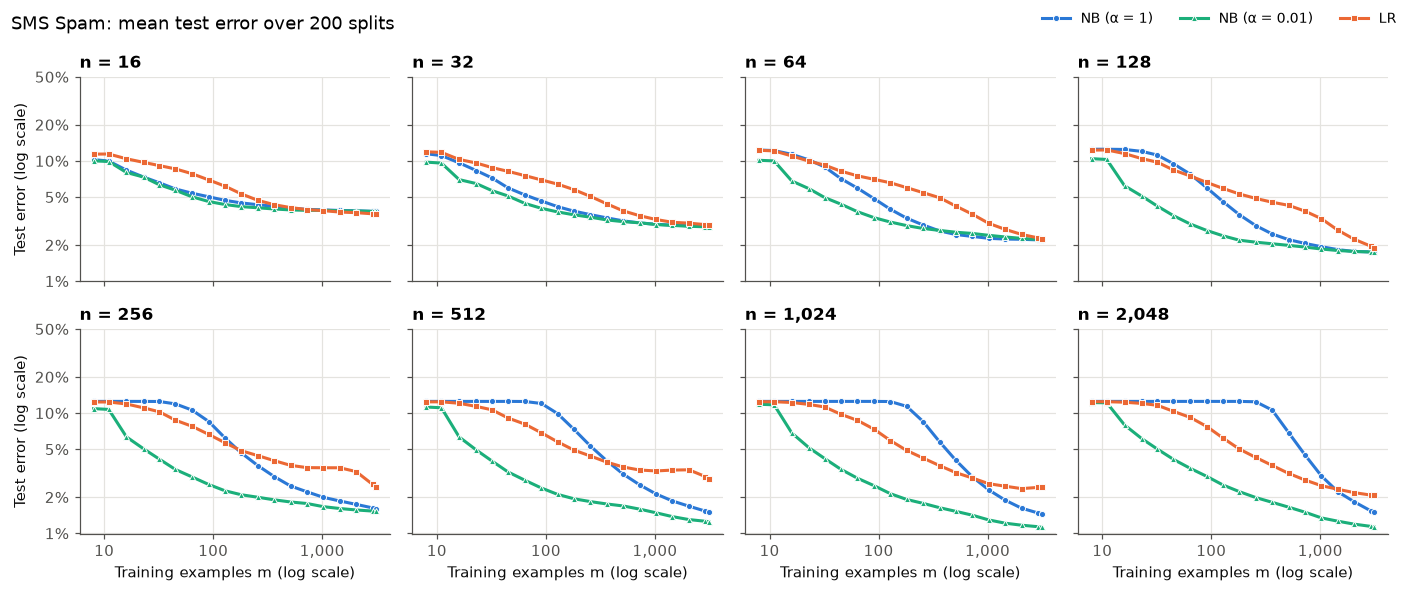

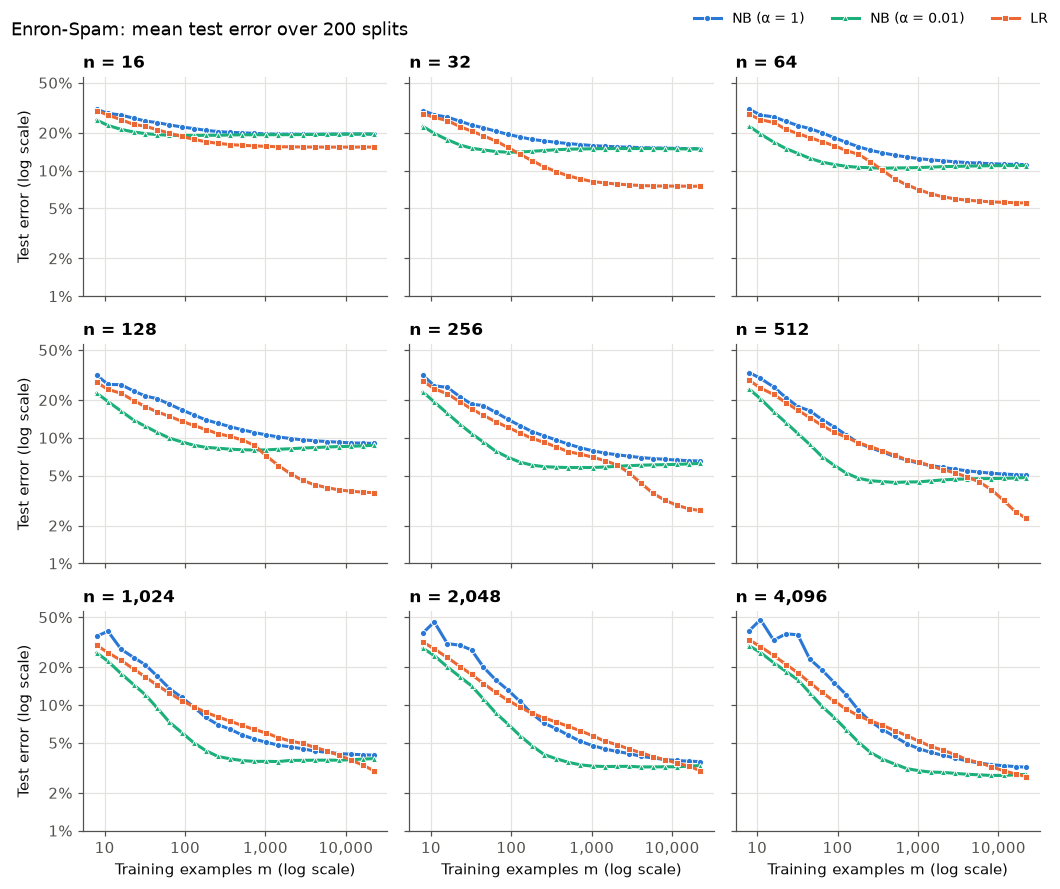

In [ ]:
SERIES = [("bnb", "NB (α = 1)", "#2a78d6", "o"), ("bnb_a001", "NB (α = 0.01)", "#1baf7a", "^"), ("lr", "LR", "#eb6834", "s")]
thousands = FuncFormatter(lambda v, _p: f"{v:,.0f}")
percent = FuncFormatter(lambda v, _p: f"{v * 100:g}%")

# Plots mean test error learning curves across training sizes (m) for multiple vocabulary sizes (n) and model types
def plot_curves(df, title):
    ns = sorted(df.n.unique())
    ncols = 3 if len(ns) == 9 else 4
    nrows = int(np.ceil(len(ns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.7 * nrows), sharex=True, sharey=True, squeeze=False)
    for ax, n in zip(axes.ravel(), ns):
        for name, label, color, marker in SERIES:
            curve = mean_table(df[df.n == n], name)[n]
            ax.plot(curve.index, curve.values, marker=marker, color=color, markersize=4,
                    markeredgecolor="white", markeredgewidth=0.6, label=label)
        ax.set_title(f"n = {n:,}")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.xaxis.set_major_formatter(thousands)
        ax.yaxis.set_major_formatter(percent)
        ax.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2, 0.5])
        ax.minorticks_off()
    for ax in axes.ravel()[len(ns):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Training examples m (log scale)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Test error (log scale)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncols=3, fontsize=9)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    fig.tight_layout()
    plt.show()


plot_curves(sms, "SMS Spam: mean test error over 200 splits")
plot_curves(enron, "Enron-Spam: mean test error over 200 splits")

In [21]:
for name, df in (("sms", sms), ("enron", enron)):
    ns = sorted(df.n.unique())
    m_top = df.m.max()
    rows = {}
    for gen in ("bnb", "bnb_a001"):
        for metric in ("test_error", "test_logloss"):
            diff = mean_table(df, gen, metric) - mean_table(df, "lr", metric)
            rows[f"{gen} vs lr, {metric}"] = [rough_crossover(diff[n]) for n in ns]
    banner(f"{name}: rough crossover m*(n) - first m from which LR stays better on average")
    print(pd.DataFrame(rows, index=pd.Index(ns, name="n")).T.to_string())

    banner(f"{name}: mean test error at the largest training size (m = {m_top:,})")
    top = df[df.m == m_top].pivot_table(index="model", columns="n", values="test_error", aggfunc="mean")
    print(top.to_string(float_format=lambda v: f"{v:.4f}"))

    banner(f"{name}: logistic regression fit health")
    lr = df[df.model == "lr"]
    health = pd.DataFrame({
        "separable fits": lr.groupby("n").train_error.apply(lambda v: v.eq(0).mean()),
        "largest separable m": lr[lr.train_error.eq(0)].groupby("n").m.max(),
        "not converged": lr.groupby("n").converged.apply(lambda v: int((~v).sum())),
        "max iterations": lr.groupby("n").n_iter.max()})
    print(health.to_string(float_format=lambda v: f"{v:.1%}"))

    for metric in ("test_error", "test_logloss"):
        g = df.groupby(["n", "model", "m"])[metric]
        summary = pd.DataFrame({"mean": g.mean(), "ci95": 1.96 * g.std() / np.sqrt(g.count()), "splits": g.count()})
        summary.reset_index().to_csv(RESULTS / name / f"summary_{metric}.csv", index=False)
    print(f"\n{len(df):,} result rows; summaries saved to {RESULTS / name}")


sms: rough crossover m*(n) - first m from which LR stays better on average
n                              16       32       64       128      256      512      1024     2048
bnb vs lr, test_error           724  > 3,128  > 3,128  > 3,128  > 3,128  > 3,128  > 3,128  > 3,128
bnb vs lr, test_logloss       2,048    2,048    2,896    3,128  > 3,128  > 3,128  > 3,128  > 3,128
bnb_a001 vs lr, test_error    1,024  > 3,128  > 3,128  > 3,128  > 3,128  > 3,128  > 3,128  > 3,128
bnb_a001 vs lr, test_logloss  1,448    2,048    2,896  > 3,128  > 3,128  > 3,128  > 3,128  > 3,128

sms: mean test error at the largest training size (m = 3,128)
n          16     32     64     128    256    512    1024   2048
model                                                           
bnb      0.0380 0.0287 0.0219 0.0174 0.0160 0.0151 0.0145 0.0150
bnb_a001 0.0380 0.0282 0.0222 0.0173 0.0153 0.0125 0.0112 0.0113
lr       0.0361 0.0294 0.0226 0.0190 0.0242 0.0283 0.0245 0.0207
lr_l2    0.0403 0.0324 0.0242 0.0196 0.01

n          16     32     64     128    256    512    1024   2048   4096
model                                                                  
bnb      0.1952 0.1494 0.1116 0.0903 0.0654 0.0504 0.0399 0.0355 0.0320
bnb_a001 0.1952 0.1487 0.1096 0.0871 0.0625 0.0482 0.0374 0.0330 0.0281
lr       0.1539 0.0751 0.0552 0.0366 0.0264 0.0229 0.0301 0.0301 0.0269
lr_l2    0.1538 0.0753 0.0554 0.0370 0.0263 0.0207 0.0181 0.0163 0.0148
mnb      0.2498 0.1521 0.1129 0.0757 0.0454 0.0353 0.0272 0.0240 0.0202

enron: logistic regression fit health
      separable fits  largest separable m  not converged  max iterations
n                                                                       
16              5.5%                   45              0             996
32             19.5%                  128              0            1405
64             29.8%                  362              0            2183
128            41.8%                  724              0            3264
256            47.1

Across both corpora, the learning-curve crossover (NB α = 0.01 vs. LR) grows with n (reaching m = 91 to 22,110 on Enron, and only n = 16 on SMS before running out of data) with log-loss crossovers landing later than error crossovers.

* **Error crossovers:** Enron: 91 → 22,110 as n goes 16 → 4,096 (α = 0.01); LR leads from the first training size for n ≤ 256 under the paper's α = 1. SMS only reaches a crossover at n = 16, for either α.
* **Error at the largest training size:** SMS best is NB α = 0.01 at 1.1% (n = 1,024–2,048). Enron best is L2-regularized LR at 1.5% (n = 4,096), unregularized LR peaks at n = 512 (2.3%) then worsens.
* **Fit diagnostics:** All 73,600 LR fits converged; the separable-fit share rises with n (28% → 100% on SMS, 6% → 75% on Enron).
* **TO DO:** implement CIs and significance tests

## 9. Pipeline Change Summary

| Stage | Initial attempt | Problem found | Updated pipeline |
|---|---|---|---|
| Design | SMS only, n up to 4,096 | Dev split has 3,362 distinct tokens; largest training set is 1.5 times n at n = 2,048 | SMS n = 16 to 2,048; Enron n = 16 to 4,096 |
| Data | `CountVectorizer(max_features=n)` on all messages, random split | 11.6% of test messages duplicated in train; vocabulary chosen with test messages; stopword features; "£", "!", "i" dropped | Remove duplicates, EDA tokenizer, MI ranking on a 20% stratified dev split, nested top-n vocabularies |
| Models | `LogisticRegression(C=np.inf)` with defaults, `log_loss` | Separable training sets: the fit depends on the stopping rule; log-loss understated | LR with C = 10,000, `tol=1e-8`; separable fits flagged; all models scored from log-odds |
| Loop | Fresh random splits per (n, m), 20 repetitions, round-number m | One-class training sets skipped; unpaired noise; gap smaller than its CI | 200 paired stratified splits, nested training sets, log-spaced m, results saved per n |
| Smoothing | α = 1 only, then α tuned on the test set or by cross-validation | α = 1 predicts all ham at large n and small m; tuning biases the comparison or is impossible at small m | Keep α = 1; add one fixed α = 0.01 variant |
| Data size | Shrink the SMS test set to 200 | A third of a doubling of m, with wider confidence intervals | Add Enron-Spam (largest training set 22,110) |

Models in the results files: `bnb` (NB, α = 1), `bnb_a001` (NB, α = 0.01), `lr` (C = 10,000), `lr_l2` (C = 1), `mnb` (multinomial NB). Columns: `n`, `m`, `split`, `model`, `test_error`, `test_logloss`, `train_error`, `n_iter`, `converged`.

Limitations: α = 0.01 was chosen after seeing the α = 1 results; our LR for separable data differs from the paper's; ranking by MI makes later features weaker; Enron's ham can be identified by source tokens.

## 10. CIs and Significance Corrections

Section 8's `rough_crossover` and the `mean ± 1.96 * std` confidence intervals in 7.1 was sufficient for building the pipeline, but they both assume the 200 splits are independent draws. They are not. Every split is drawn from the same pool, so test sets overlap across splits, and a naive paired t-test built on that assumption understates the true variance. We will address this here by replacing them with three corrections appropriate for resampled, overlapping train/test splits: a Nadeau & Bengio (2003) overlap-corrected paired t-test, a Holm (1979) step-down correction across the m values tested within one n, and a bootstrap confidence interval on the crossover point itself (which isn't a quantity you can run a significance test against in the first place).

### 10.1 Nadeau–Bengio corrected paired t-test

In [ ]:
from scipy import stats

#Extracts performance differences for a specific sample size n and training set size m
def paired_diffs(df, gen, dis, n, m, metric="test_error"):
    """Per-split difference metric(gen) - metric(dis) at one (n, m), one row per split."""
    g = df[(df.n == n) & (df.m == m) & (df.model == gen)].set_index("split")[metric]
    d = df[(df.n == n) & (df.m == m) & (df.model == dis)].set_index("split")[metric]
    both = g.index.intersection(d.index)
    return (g.loc[both] - d.loc[both]).to_numpy()

#Performs a paired t-test assuming the k performance differences are fully independent
def naive_paired_ttest(diffs):
    """Paired t-test that treats the k differences as independent (the textbook default)."""
    diffs = np.asarray(diffs, dtype=float)
    k = len(diffs)
    d_bar = diffs.mean()
    se = diffs.std(ddof=1) / np.sqrt(k)
    t_stat = d_bar / se if se > 0 else np.sign(d_bar) * np.inf
    p = 2 * stats.t.sf(np.abs(t_stat), df=k - 1)
    return d_bar, t_stat, p

#Performs the Nadeau & Bengio corrected paired t-test
def nb_corrected_ttest(diffs, n_train, n_test):
    """Nadeau & Bengio (2003) corrected paired t-test for k resampled, overlapping test sets.

    Inflates the naive variance by (1/k + n_test/n_train) to account for the fact that the k
    Monte Carlo test sets are drawn from the same pool and therefore are not independent."""
    diffs = np.asarray(diffs, dtype=float)
    k = len(diffs)
    d_bar = diffs.mean()
    var = diffs.var(ddof=1) * (1.0 / k + n_test / n_train)
    t_stat = d_bar / np.sqrt(var) if var > 0 else np.sign(d_bar) * np.inf
    p = 2 * stats.t.sf(np.abs(t_stat), df=k - 1)
    return d_bar, t_stat, p

#Calculates the closed-form variance inflation factor
def variance_inflation_factor(k, n_train, n_test):
    """Corrected variance / naive variance, in closed form: 1 + k * n_test / n_train. Reported
    directly (rather than as a ratio of p-values, which underflows once p gets very small)."""
    return 1.0 + k * n_test / n_train

#Evaluates naive vs. corrected p-values across all (n, m) configurations for a model pair, printing a summary of significant differences and VIF bounds
def significance_table(df, dataset, gen, dis="lr", metric="test_error", alpha=0.05):
    """Naive vs. corrected p-values at every (n, m) for one model pair."""
    cfg = DATASETS[dataset]
    n_test = cfg["test_size"]
    ns = sorted(df.n.unique())
    rows = []
    for n in ns:
        ms = sorted(df[df.n == n].m.unique())
        for m in ms:
            d = paired_diffs(df, gen, dis, n, m, metric)
            if len(d) == 0:
                continue
            _, _, p_naive = naive_paired_ttest(d)
            _, _, p_corr = nb_corrected_ttest(d, n_train=m, n_test=n_test)
            rows.append({"n": n, "m": m, "p_naive": p_naive, "p_corrected": p_corr,
                         "vif": variance_inflation_factor(len(d), m, n_test)})
    out = pd.DataFrame(rows)
    sig_naive = (out.p_naive < alpha).sum()
    sig_corr = (out.p_corrected < alpha).sum()
    print(f"{dataset}: {gen} vs {dis}, {metric} -- {len(out)} (n, m) cells tested")
    print(f"  significant at alpha={alpha} under the naive test:     {sig_naive}")
    print(f"  significant at alpha={alpha} under the corrected test: {sig_corr}")
    print(f"  variance inflation factor (closed form, 1 + k*n_test/m): "
          f"{out.vif.min():.1f}x (largest m) to {out.vif.max():,.1f}x (smallest m)")
    return out


sig_enron_a001 = significance_table(enron, "enron", "bnb_a001", "lr", "test_error"); print()
sig_enron_a1   = significance_table(enron, "enron", "bnb", "lr", "test_error"); print()
sig_sms_a001   = significance_table(sms, "sms", "bnb_a001", "lr", "test_error"); print()
sig_sms_a1     = significance_table(sms, "sms", "bnb", "lr", "test_error")


enron: bnb_a001 vs lr, test_error -- 216 (n, m) cells tested
  significant at alpha=0.05 under the naive test:     213
  significant at alpha=0.05 under the corrected test: 57
  variance inflation factor (closed form, 1 + k*n_test/m): 19.1x (largest m) to 50,001.0x (smallest m)

enron: bnb vs lr, test_error -- 216 (n, m) cells tested
  significant at alpha=0.05 under the naive test:     200
  significant at alpha=0.05 under the corrected test: 62
  variance inflation factor (closed form, 1 + k*n_test/m): 19.1x (largest m) to 50,001.0x (smallest m)

sms: bnb_a001 vs lr, test_error -- 152 (n, m) cells tested
  significant at alpha=0.05 under the naive test:     149
  significant at alpha=0.05 under the corrected test: 20
  variance inflation factor (closed form, 1 + k*n_test/m): 64.9x (largest m) to 25,001.0x (smallest m)

sms: bnb vs lr, test_error -- 152 (n, m) cells tested
  significant at alpha=0.05 under the naive test:     146
  significant at alpha=0.05 under the corrected test: 2

### 10.2 Holm correction across m

In [ ]:
# Applies the Holm-Bonferroni step-down procedure to control FWER
def holm_correction(pvals, alpha=0.05):
    """Holm (1979) step-down procedure. Returns a boolean array, same order as pvals, True
    where the null is rejected at family-wise error rate alpha."""
    pvals = np.asarray(pvals, dtype=float)
    k = len(pvals)
    order = np.argsort(pvals)
    reject = np.zeros(k, dtype=bool)
    for rank, idx in enumerate(order):
        threshold = alpha / (k - rank)
        if pvals[idx] <= threshold:
            reject[idx] = True
        else:
            break
    return reject

# Groups a significance table by 'n' and applies Holm correction to Nadeau-Bengio corrected p-values independently within each group.
def holm_by_n(sig_table, alpha=0.05):
    """Apply the Holm correction within each n separately (one family = one n's m-values),
    using the already-corrected (Nadeau-Bengio) p-values from 10.1 as the input p-values."""
    out = sig_table.copy()
    out["holm_reject"] = False
    for n, grp in out.groupby("n"):
        out.loc[grp.index, "holm_reject"] = holm_correction(grp.p_corrected.to_numpy(), alpha)
    return out

# Evaluate and print impact of Holm FWER correction across all datasets/models
for label, sig in [("enron bnb_a001 vs lr", sig_enron_a001), ("enron bnb vs lr", sig_enron_a1),
                    ("sms bnb_a001 vs lr", sig_sms_a001), ("sms bnb vs lr", sig_sms_a1)]:
    holm = holm_by_n(sig)
    before = (holm.p_corrected < 0.05).sum()
    after = holm.holm_reject.sum()
    print(f"{label}: significant cells before Holm = {before}, after Holm = {after} (of {len(holm)})")

holm_enron_a001 = holm_by_n(sig_enron_a001)


enron bnb_a001 vs lr: significant cells before Holm = 57, after Holm = 49 (of 216)
enron bnb vs lr: significant cells before Holm = 62, after Holm = 55 (of 216)
sms bnb_a001 vs lr: significant cells before Holm = 20, after Holm = 11 (of 152)
sms bnb vs lr: significant cells before Holm = 20, after Holm = 10 (of 152)


### 10.3 Bootstrap confidence intervals on the crossover point

In [ ]:
# Finds the log-linearly interpolated crossover point where model dis takes over gen
def interpolated_crossover(ms, diff_means):
    """Smallest m from which dis (e.g. LR) stays ahead of gen (e.g. NB) for every larger m in
    the grid, i.e. diff = mean(gen) - mean(dis) stays positive to the end. Linearly interpolated
    in log m between the last m where gen led and the first m where dis takes over for good.
    Returns None if dis never takes over within the grid (right-censored)."""
    ms = np.asarray(ms, dtype=float)
    d = np.asarray(diff_means, dtype=float)
    ahead = d > 0
    if not ahead[-1]:
        return None                      # censored: dis never gets ahead and stays there
    if ahead.all():
        return float(ms[0])              # censored low: dis is ahead from the first m
    i = len(ahead) - 1
    while i > 0 and ahead[i - 1]:
        i -= 1
    x0, x1 = np.log(ms[i - 1]), np.log(ms[i])
    y0, y1 = d[i - 1], d[i]
    frac = (0.0 - y0) / (y1 - y0)
    return float(np.exp(x0 + frac * (x1 - x0)))

# Computes a point estimate and 95% bootstrap CI for crossover m*(n) via split resampling
def bootstrap_crossover(df, gen, dis, n, metric="test_error", n_boot=2000, seed=0):
    """Point estimate of the crossover m*(n) plus a 95% bootstrap CI, resampling the 200
    splits with replacement and recomputing the crossover each time."""
    sub = df[(df.n == n) & (df.model.isin([gen, dis]))]
    ms = sorted(sub.m.unique())
    piv = sub.pivot_table(index="split", columns=["model", "m"], values=metric)
    gen_vals = piv[gen][ms].to_numpy()
    dis_vals = piv[dis][ms].to_numpy()
    diffs = gen_vals - dis_vals          # one row per split, one column per m
    point = interpolated_crossover(ms, diffs.mean(axis=0))
    rng = np.random.default_rng(seed)
    k = diffs.shape[0]
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, k, size=k)
        boots.append(interpolated_crossover(ms, diffs[idx].mean(axis=0)))
    censored = sum(b is None for b in boots)
    vals = np.array([b for b in boots if b is not None], dtype=float)
    if len(vals) == 0:
        return point, None, None, censored
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return point, lo, hi, censored

#Generates a summary table of crossover points and bootstrap CIs across vocabulary sizes
def crossover_table(df, dataset, gen, dis="lr", metric="test_error", n_boot=2000):
    """m*(n) with 95% bootstrap CI at every vocabulary size, the table-3-style summary."""
    ns = sorted(df.n.unique())
    rows = []
    for n in ns:
        point, lo, hi, censored = bootstrap_crossover(df, gen, dis, n, metric, n_boot)
        rows.append({"n": n, "m_star": point, "ci_lo": lo, "ci_hi": hi,
                      "censored_resamples": censored, "of": n_boot})
    out = pd.DataFrame(rows).set_index("n")
    print(f"\n{dataset}: {gen} vs {dis}, {metric} -- crossover m*(n) with 95% bootstrap CI ({n_boot} resamples)")
    print(out.to_string(float_format=lambda v: f"{v:,.0f}" if pd.notna(v) else "NA"))
    return out


# NB (alpha = 0.01 and alpha = 1) vs LR on Enron-Spam test error -- crossover m*(n)
crossover_enron_a001 = crossover_table(enron, "enron", "bnb_a001", "lr", "test_error")
crossover_enron_a1   = crossover_table(enron, "enron", "bnb", "lr", "test_error")
# SMS test error, for both smoothing variants
crossover_sms_a001   = crossover_table(sms, "sms", "bnb_a001", "lr", "test_error")
crossover_sms_a1     = crossover_table(sms, "sms", "bnb", "lr", "test_error")

sub = crossover_enron_a001.dropna(subset=["m_star"])
logn, logm = np.log(sub.index.to_numpy()), np.log(sub.m_star.to_numpy())
slope, intercept = np.polyfit(logn, logm, 1)
print(f"\nEnron bnb_a001 vs lr: power-law fit m* = c * n^k over the {len(sub)} uncensored n -> k = {slope:.3f}")


enron: bnb_a001 vs lr, test_error -- crossover m*(n) with 95% bootstrap CI (2000 resamples)
      m_star  ci_lo  ci_hi  censored_resamples    of
n                                                   
16        81     74     89                   0  2000
32       115    109    122                   0  2000
64       332    318    348                   0  2000
128      850    824    875                   0  2000
256    2,189  2,103  2,272                   0  2000
512    4,695  4,420  4,984                   0  2000
1024  11,331 10,613 12,122                   0  2000
2048  15,981 14,699 17,207                   0  2000
4096  17,844 15,657 20,225                   1  2000

enron: bnb vs lr, test_error -- crossover m*(n) with 95% bootstrap CI (2000 resamples)
      m_star  ci_lo  ci_hi  censored_resamples    of
n                                                   
16         8      8     10                   0  2000
32         8      8      8                   0  2000
64         8      8      

The corrected procedures show us that far fewer cells are actually significant once split overlap and multiple comparisons are accounted for, and the crossover point now comes with an confidence interval (10.3 ci_lo to ci_hi) instead of a single number.

* The crossover table in 10.3 confirms the pattern from Section 8: on Enron (NB α = 0.01 vs. LR), m* grows roughly as a power law in n (fitted exponent k ≈ 1.085 over the 9 uncensored n), closely tracking the grid-read crossovers from Section 8 (e.g. n = 64: m* ≈ 332 [318, 348]; n = 1,024: m* ≈ 11,331 [10,613, 12,122]).
* The Holm correction in 10.2 shows: of the 57 of 216 Enron (n, m) cells significant under the Nadeau–Bengio test for `bnb_a001` vs. `lr`, only 49 survive the within-n family correction. SMS loses nearly half its naively-significant cells under Holm (20 → 11 for `bnb_a001`).
* The SMS `bnb` (α = 1) crossover at n = 16: only read informally off the curve initially as "LR ahead from m = 724" resolves to m* ≈ 657, 95% bootstrap CI [466, 1,034].

## 11. Confusion matrices

Test error counts every mistake the same way, so it can't tell us whether a model is missing spam or flagging ham. We will look at the confusion matrix (spam = positive class) at four settings that cover both regimes and the α = 1 failure:

* **Enron, n = 512:** m = 64 (NB α = 0.01 ahead) and the largest m = 22,110 (LR ahead).
* **SMS, n = 2,048:** m = 64 (where NB α = 1 was stuck at 12.5% error) and the largest m = 3,128.


In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

RESULTS, PROCESSED = Path("results"), Path("data/processed")

# (dataset, n, m); m = None means the largest training size in that corpus's sweep
CONF_SETTINGS = [("enron", 512, 64), ("enron", 512, None), ("sms", 2048, 64), ("sms", 2048, None)]
CONF_MODELS = ["bnb", "bnb_a001", "lr"]
COUNT_COLS = ["tn", "fp", "fn", "tp"]

# Counts the four confusion-matrix cells from log-odds z and labels y (spam is the positive class)
def confusion_counts(z, y):
    pred, spam = z > 0, y == 1
    return {"tn": int(np.sum(~pred & ~spam)), "fp": int(np.sum(pred & ~spam)),
            "fn": int(np.sum(~pred & spam)), "tp": int(np.sum(pred & spam))}

# Refits the three models on one paired split at one training size and returns their test confusion counts
def confusion_one_split(X_counts, y, split_id, m, test_size, seed):
    X = {"counts": X_counts, "binary": (X_counts > 0).astype(np.float64)}
    s = Split(y, split_id, test_size, seed)
    tr = s.train(m)
    rows = []
    for name in CONF_MODELS:
        Xs = X[MODELS[name][0]]
        model = MODELS[name][1]().fit(Xs[tr], y[tr])
        rows.append({"split": split_id, "model": name, **confusion_counts(log_odds(model, Xs[s.test]), y[s.test])})
    return rows

# Builds results/confusion.csv: one row per (setting, split, model), on the same splits as the sweep
def build_confusion():
    frames = []
    for ds, n, m in CONF_SETTINGS:
        X = sp.load_npz(PROCESSED / ds / "pool_counts.npz").tocsc()[:, :n].tocsr()
        y = np.load(PROCESSED / ds / "pool_labels.npy")
        cfg = json.loads((RESULTS / ds / "raw" / f"n{n:04d}.config.json").read_text())
        m = m or cfg["m_grid"][-1]
        rows = Parallel(n_jobs=-1)(delayed(confusion_one_split)(X, y, s, m, cfg["test_size"], cfg["seed"])
                                   for s in range(cfg["splits"]))
        df = pd.DataFrame([r for rr in rows for r in rr])
        df.insert(0, "m", m)
        df.insert(0, "n", n)
        df.insert(0, "dataset", ds)
        frames.append(df)
        print(f"  {ds} n = {n}, m = {m:,}: refitted {len(CONF_MODELS)} models on {cfg['splits']} splits")
    return pd.concat(frames, ignore_index=True)


conf_path = RESULTS / "confusion.csv"
if conf_path.exists():
    confusion = pd.read_csv(conf_path)
    print(f"loaded {conf_path.as_posix()} ({len(confusion):,} rows); delete the file to refit")
else:
    # needs the cells that define MODELS (3.2, 6.3) and Split (4.2) to have been run
    confusion = build_confusion()
    confusion.to_csv(conf_path, index=False)
    print(f"saved {conf_path.as_posix()} ({len(confusion):,} rows)")

# check: the confusion counts reproduce the test error the sweep saved for the same (n, m, split, model)
for ds in confusion.dataset.unique():
    raw = pd.concat([pd.read_csv(p) for p in sorted((RESULTS / ds / "raw").glob("n*.csv"))], ignore_index=True)
    both = confusion[confusion.dataset == ds].merge(raw, on=["n", "m", "split", "model"])
    err = (both.fp + both.fn) / both[COUNT_COLS].sum(axis=1)
    print(f"{ds}: {len(both):,} fits matched to the sweep, largest |error difference| = {(err - both.test_error).abs().max():.4f}")

conf_mean = confusion.groupby(["dataset", "n", "m", "model"], sort=False)[COUNT_COLS].mean()
conf_mean["ham_correct_rate"] = conf_mean.tn / (conf_mean.tn + conf_mean.fp)                    # specificity
conf_mean["spam_recall"] = conf_mean.tp / (conf_mean.tp + conf_mean.fn)                         # sensitivity
conf_mean["spam_precision"] = conf_mean.tp / (conf_mean.tp + conf_mean.fp).replace(0, np.nan)   # NaN: never predicts spam
conf_mean["error"] = (conf_mean.fp + conf_mean.fn) / conf_mean[COUNT_COLS].sum(axis=1)
conf_mean.reset_index().to_csv(RESULTS / "confusion_summary.csv", index=False)
print("\nmean test confusion counts over splits (spam = positive class)")
print(conf_mean.round(3).to_string())

loaded results/confusion.csv (2,400 rows); delete the file to refit
enron: 1,200 fits matched to the sweep, largest |error difference| = 0.0000


sms: 1,200 fits matched to the sweep, largest |error difference| = 0.0000

mean test confusion counts over splits (spam = positive class)
                                   tn       fp       fn       tp  ham_correct_rate  spam_recall  spam_precision  error
dataset n    m     model                                                                                              
enron   512  64    bnb        781.455  253.545   26.085  938.915             0.755        0.973           0.787  0.140
                   bnb_a001   935.475   99.525   42.045  922.955             0.904        0.956           0.903  0.071
                   lr         873.235  161.765   89.295  875.705             0.844        0.907           0.844  0.126
             22110 bnb        939.335   95.665    5.220  959.780             0.908        0.995           0.909  0.050
                   bnb_a001   943.560   91.440    5.020  959.980             0.912        0.995           0.913  0.048
                   lr        

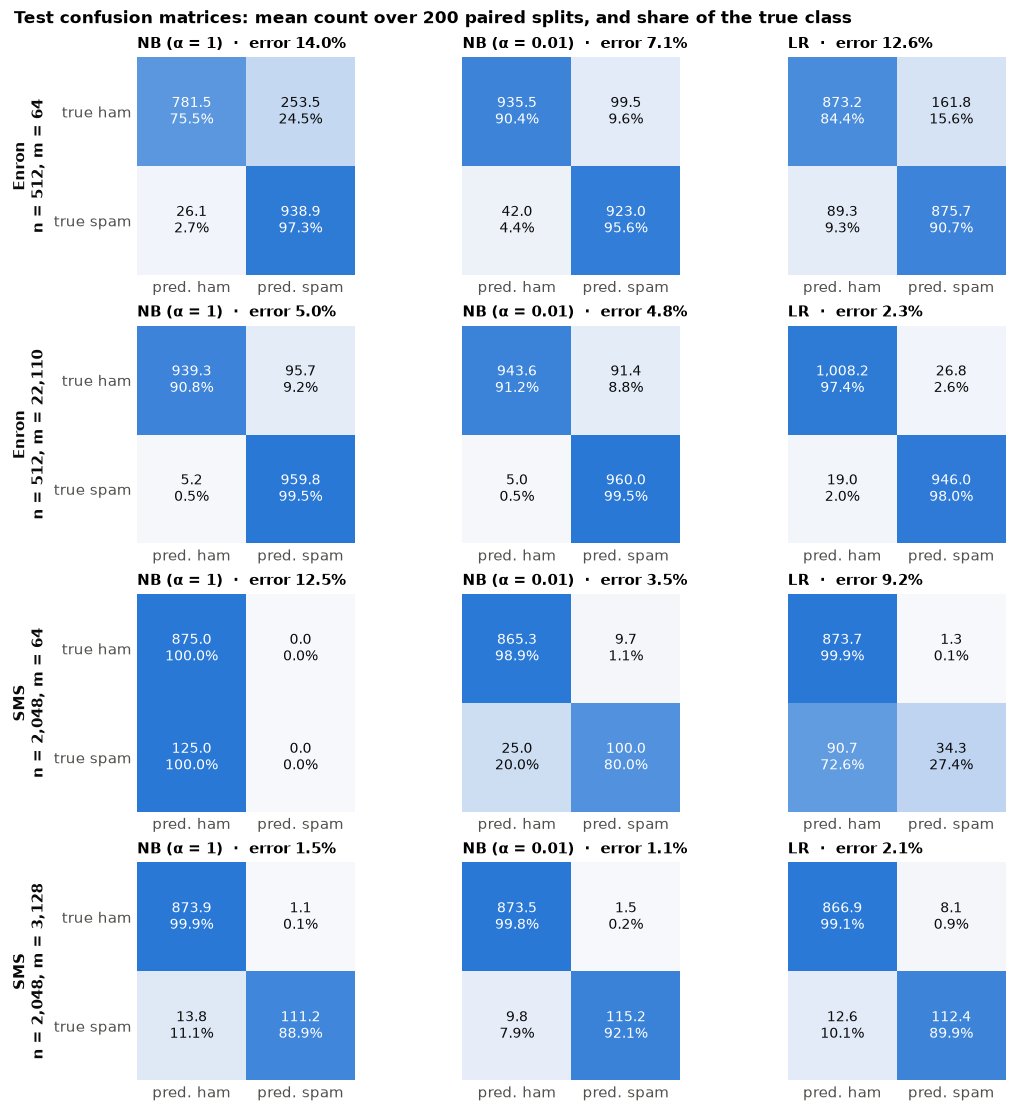

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

CONF_LABELS = {"bnb": "NB (α = 1)", "bnb_a001": "NB (α = 0.01)", "lr": "LR"}
CONF_CMAP = LinearSegmentedColormap.from_list("conf", ["#f6f8fb", "#2a78d6"])

# Draws one 2x2 confusion matrix per (setting, model): mean counts over splits, shaded by share of the true class
def plot_confusion(conf_mean):
    settings = list(dict.fromkeys(idx[:3] for idx in conf_mean.index))
    fig, axes = plt.subplots(len(settings), len(CONF_MODELS), figsize=(9.6, 2.5 * len(settings)), constrained_layout=True)
    for r, (ds, n, m) in enumerate(settings):
        for c, name in enumerate(CONF_MODELS):
            ax, row = axes[r, c], conf_mean.loc[(ds, n, m, name)]
            counts = np.array([[row.tn, row.fp], [row.fn, row.tp]])
            share = counts / counts.sum(axis=1, keepdims=True)
            ax.imshow(share, cmap=CONF_CMAP, vmin=0, vmax=1)
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{counts[i, j]:,.1f}\n{share[i, j]:.1%}", ha="center", va="center",
                            fontsize=9, color="white" if share[i, j] > 0.55 else "#0b0b0b")
            ax.set_xticks([0, 1], ["pred. ham", "pred. spam"])
            ax.set_yticks([0, 1], ["true ham", "true spam"] if c == 0 else ["", ""])
            ax.tick_params(length=0)
            ax.grid(False)
            for side in ax.spines.values():
                side.set_visible(False)
            ax.set_title(f"{CONF_LABELS[name]}  ·  error {row.error:.1%}", fontsize=10, loc="left")
            if c == 0:
                ax.set_ylabel(f"{'Enron' if ds == 'enron' else 'SMS'}\nn = {n:,}, m = {m:,}", fontsize=10, fontweight="bold")
    fig.suptitle("Test confusion matrices: mean count over 200 paired splits, and share of the true class",
                 fontsize=11, fontweight="bold", x=0.01, ha="left")
    plt.show()


plot_confusion(conf_mean)

The confusion counts reproduce the sweep's saved test error exactly at all 2,400 fits, and they show that the two models make different kinds of mistakes, not just different numbers of them.

* **The α = 1 failure is all missed spam:** On SMS at n = 2,048, m = 64, NB (α = 1) predicts ham for every one of the 1,000 test messages in every split (0 of 125 spam caught), which is why its error equals the spam rate of 12.5%. With α = 0.01 it catches 80% of spam at the cost of about 10 false alarms.
* **LR at small m on SMS is also mostly missed spam:** It catches only 27% of spam at m = 64 (about 91 of 125 missed) while flagging almost no ham, so its 9.2% error is nearly all false negatives.
* **On Enron the errors are mostly false alarms:** At n = 512, m = 64, NB (α = 1) flags 24.5% of ham as spam, NB (α = 0.01) 9.6% and LR 15.6%. NB's lead at small m comes from fewer false alarms and fewer missed spam.
* **LR's win at large m on Enron comes from ham:** At m = 22,110 both NB variants still flag about 9% of ham (roughly 92 of 1,035), against 2.6% for LR. NB catches slightly more spam (99.5% vs. 98.0%), but that does not make up for it: 4.8% error against 2.3%.
* **On SMS at the largest m, NB (α = 0.01) is ahead on both classes:** 92.1% spam recall and 1.5 false alarms, against 89.9% and 8.1 for LR.

Each figure is a mean over 200 paired splits at one setting, so these describe four points on the curves in Section 8, not the whole grid.


### 11.1 Analysis

Each pattern follows from how the two models use their training data. The first point is measured in Section 6.1; the others are our interpretation of the counts and were not tested directly.

* **NB (α = 1) calls everything ham (SMS, m = 64):** A training set of 64 has only 8 spam messages. Smoothing gives every unseen word probability 1/10 in spam but 1/58 in ham, so each *absent* word is a small vote for ham. A text contains only a few of the 2,048 vocabulary words, so about 2,000 small votes add up to -185 on the log-odds against +29 from the words present. With α = 0.01 those votes nearly vanish, which is why it catches 80% of spam.
* **LR misses most spam at small m (SMS):** It has seen 8 spam messages, so it has learned weights for only a handful of spam words and every other weight is near zero. A new spam message using different words gets no push towards spam, and the 87% ham majority wins by default. It rarely flags ham but catches only 27% of spam.
* **Enron's mistakes are false alarms instead:** Enron is about half spam, so there is no majority class to fall back on. The top-ranked words are ham markers ("enron", "vince", "ect"), so a legitimate email that happens to lack them looks like spam.
* **LR wins at large m by clearing ham (Enron, m = 22,110):** NB treats every word as independent evidence, so correlated words are counted several times and it stays overconfident. More data cannot fix that: both NB variants stay at about 9% false alarms and α no longer matters. LR fits its weights jointly and corrects for the overlap, dropping to 2.6%. This is the paper's claim that NB converges quickly, but to a worse limit.
* **NB still leads on SMS at the largest m:** 3,128 messages is only 1.5 times the 2,048 features, so LR has not had enough data to reach its limit. This is the "crossover lies beyond the data" case from Section 6.3.